# Shape dual occlusion

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
cd "/app/"

/app


In [3]:
%run env.py
%run run.py connect

/opt/conda/lib/python3.11/site-packages/datajoint/settings.py:1039: UserWarning: No datajoint.json found. Using defaults and environment variables. Run `dj.config.save_template()` to create a template configuration.
  config = _create_config()


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.cm as cm
import seaborn as sns
import numpy as np
from vr4mice.analysis import plotting, regression, utils
from vr4mice.schema import base_analysis
from vr4mice.analysis.analysis import style
from vr4mice.schema.interpolated_trajectories import InterpolatedTrials
from vr4mice.schema.session_metrics import TrialMetrics
from vr4mice.schema.decision import InclusionStatus, ExperimentMember, LabelSet, Label, PredictionModel10Windows, DecisionPoints10Windows

from statsmodels.stats.anova import AnovaRM
from scipy.stats import ttest_ind
import scipy.stats as stats

from scipy.stats import pearsonr
from mpl_toolkits.axes_grid1 import make_axes_locatable
from scipy.spatial import ConvexHull

style()

save_fig_path = "notebooks/shape_figures/shape_figures/shape_"

In [5]:
task_type_key = {"set_name": "shape_pacman_target",
                 "stage_name": "dual_occlusion"}

BATCH_NAME = "batch1"

In [6]:
sessions_list = list(
                (InclusionStatus * ExperimentMember & {"included": 1} & task_type_key & {"batch_name": BATCH_NAME}).fetch(
                    "dataset"
                )
            )

sessions_list

/tmp/ipykernel_77212/3425963734.py:2: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  (InclusionStatus * ExperimentMember & {"included": 1} & task_type_key & {"batch_name": BATCH_NAME}).fetch(


['Uguisu_2024-09-23_1',
 'Uguisu_2024-09-24_1',
 'Vegavis_2024-09-23_1',
 'Vegavis_2024-09-25_1',
 'Vegavis_2024-09-26_1']

In [7]:
# This takes a while to fetch because we need to fetch data for all trials
dataset_list = []
for d in sessions_list:
    print(d)
    try:
        dataset_list.append(pd.DataFrame((InterpolatedTrials() & f'dataset = "{d}"').fetch(as_dict=True)[0]))
    except Exception as err:
        print(err, " dataset missing")
interpolated_df = pd.concat(dataset_list)
interpolated_df["mouse_name"] = interpolated_df.dataset.str.split("_").str[0]

Uguisu_2024-09-23_1


/tmp/ipykernel_77212/2634139630.py:6: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  dataset_list.append(pd.DataFrame((InterpolatedTrials() & f'dataset = "{d}"').fetch(as_dict=True)[0]))


Uguisu_2024-09-24_1


/tmp/ipykernel_77212/2634139630.py:6: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  dataset_list.append(pd.DataFrame((InterpolatedTrials() & f'dataset = "{d}"').fetch(as_dict=True)[0]))


Vegavis_2024-09-23_1


/tmp/ipykernel_77212/2634139630.py:6: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  dataset_list.append(pd.DataFrame((InterpolatedTrials() & f'dataset = "{d}"').fetch(as_dict=True)[0]))


Vegavis_2024-09-25_1


/tmp/ipykernel_77212/2634139630.py:6: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  dataset_list.append(pd.DataFrame((InterpolatedTrials() & f'dataset = "{d}"').fetch(as_dict=True)[0]))


Vegavis_2024-09-26_1


/tmp/ipykernel_77212/2634139630.py:6: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  dataset_list.append(pd.DataFrame((InterpolatedTrials() & f'dataset = "{d}"').fetch(as_dict=True)[0]))


In [8]:
box_df = base_analysis.BoxDataFrame().get_data(key={"dataset": "Pheasant_2024-08-15_2"})

## Regression variables traces

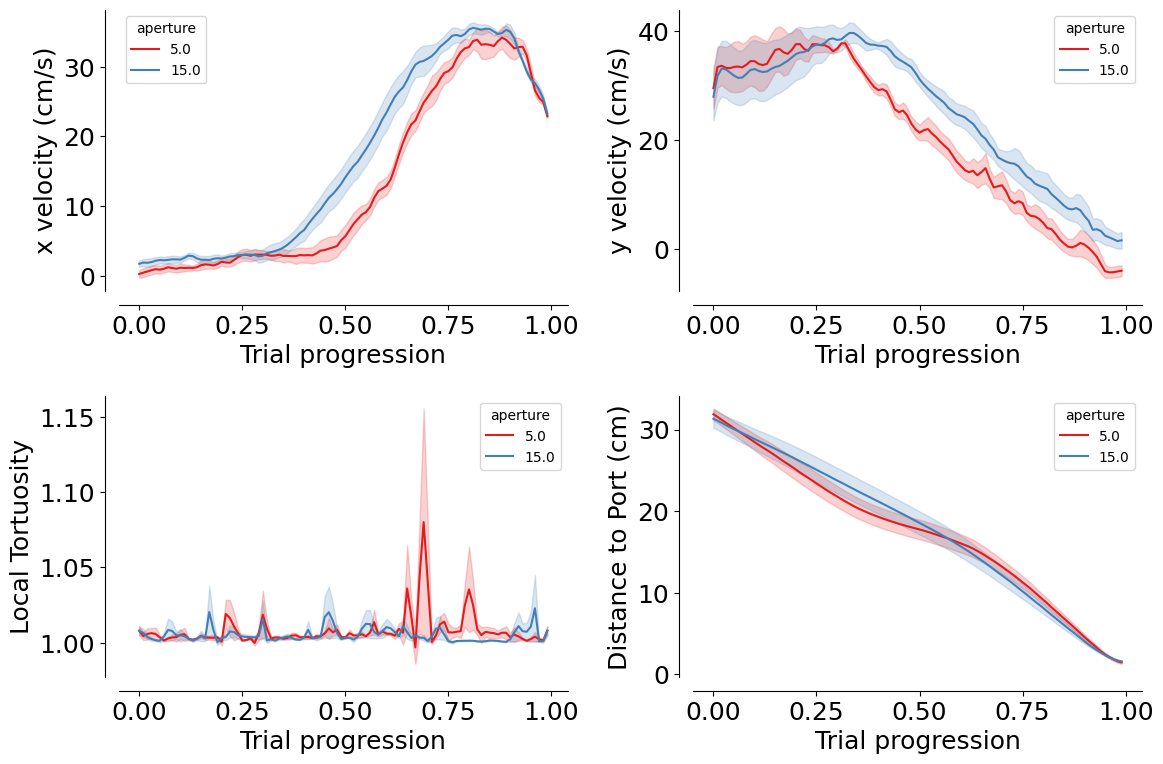

In [9]:
mean_mouse = interpolated_df.groupby(
    ["dataset", "aperture", "trial_length"], as_index=False
).mean(numeric_only=True)

fig, ax = plt.subplots(2, 2, figsize=(12, 8))
ax = ax.flatten()

for (i, label), label_str in zip(enumerate(
    ["velocity_x_fliped", "velocity_y", "local_tortuosity", "distance_to_choice"]
), ["x velocity (cm/s)", "y velocity (cm/s)", "Local Tortuosity", "Distance to Port (cm)"]):
    sns.lineplot(
        data=mean_mouse,
        x="trial_length",
        y=label,
        palette=(
            plotting.colors_aperture[:2]
            if len(mean_mouse.aperture.unique()) == 2
            else "viridis"
        ),
        hue="aperture",
        errorbar="se",
        ax=ax[i],
    )
    ax[i].set_ylabel(label_str)
    ax[i].set_xlabel("Trial progression")
    sns.despine(ax=ax[i], offset=10)
    
plt.tight_layout(pad=2)
plt.savefig(save_fig_path + "figure4_velocity_tortuosity_distance.svg", bbox_inches="tight", transparent=True)

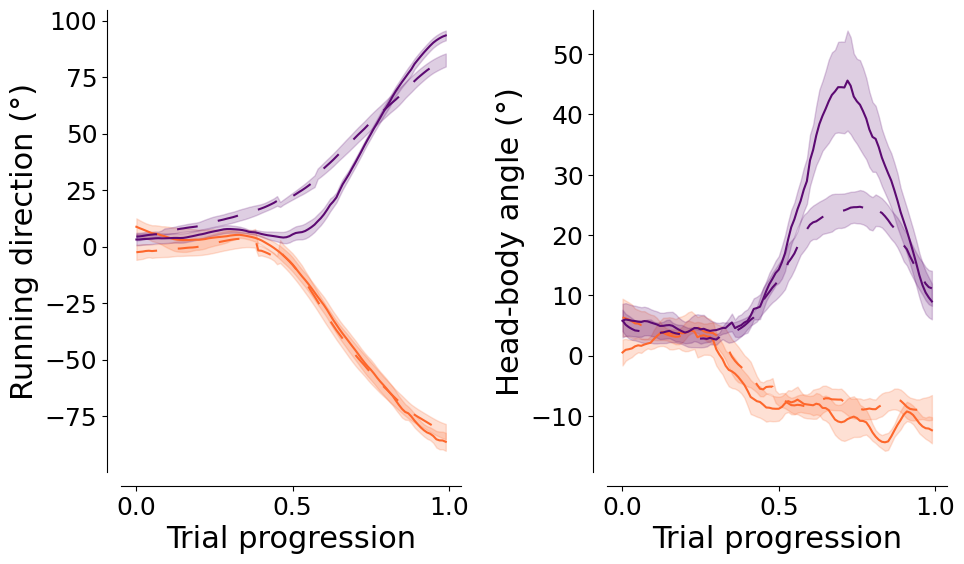

In [10]:
mean_mouse = interpolated_df.groupby(
    ["dataset", "aperture", "trial_left_choice", "trial_length"], as_index=False
).mean(numeric_only=True)

fig, ax = plt.subplots(1, 2, figsize=(10, 6))
ax = ax.flatten()

dash_styles = {
    mean_mouse.aperture.unique()[0]: "",         # Solid
    mean_mouse.aperture.unique()[1]: (10, 10)      # Dashed
}

for (i, label), label_str in zip(enumerate(["heading_dir", "head_angle"]), 
                                 ["Running direction (°)", "Head-body angle (°)"]):
    sns.lineplot(
        data=mean_mouse,
        x="trial_length",
        y=label,
        palette=plotting.colors_choice[::-1]
        if len(mean_mouse.aperture.unique()) == 2
        else "viridis",
        hue="trial_left_choice"
        if len(mean_mouse.aperture.unique()) == 2
        else "aperture",
        style=(
            "aperture"
            if len(mean_mouse.aperture.unique()) == 2
            else "trial_left_choice"
        ),
        errorbar="se",
        dashes=dash_styles,
        ax=ax[i],
    )
    ax[i].set_ylabel(label_str, fontsize=22)
    ax[i].set_xlabel("Trial progression", fontsize=22)
    sns.despine(ax=ax[i], offset=10)

    ax[i].legend().remove()
plt.tight_layout(pad=2)
plt.savefig(save_fig_path + "figure4_heading_dir_head_angle.svg", bbox_inches="tight", transparent=True)
plt.savefig(save_fig_path + "figure4_heading_dir_head_angle.png", bbox_inches="tight", transparent=True, dpi=300)

In [11]:
interpolated_df["mouse_name"] = interpolated_df.dataset.str.split("_").str[0]
interpolated_df["heading_dir_flipped"] = interpolated_df.heading_dir * interpolated_df.flip_one_side
interpolated_df["head_angle_flipped"] = interpolated_df.head_angle * interpolated_df.flip_one_side

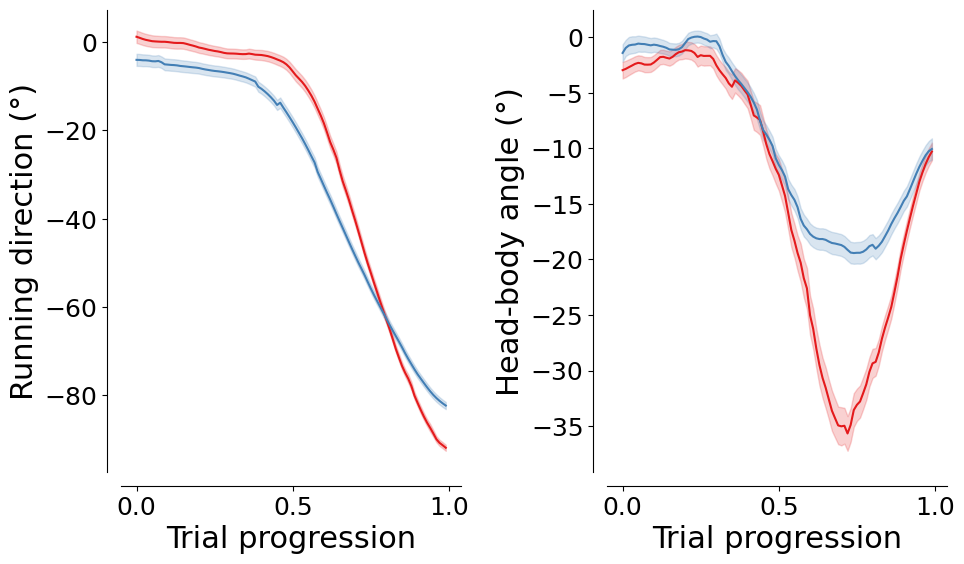

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(10, 6))
ax = ax.flatten()

sns.lineplot(
    data=interpolated_df,
    x="trial_length",
    y="heading_dir_flipped",
    hue="aperture",
    errorbar="se",
    palette=plotting.colors_aperture,
    ax=ax[0],
)
ax[0].set_ylabel("Running direction (°)", fontsize=22)
ax[0].set_xlabel("Trial progression", fontsize=22)
sns.despine(ax=ax[0], offset=10)
ax[0].legend([], [], frameon=False)

sns.lineplot(
    data=interpolated_df,
    x="trial_length",
    y="head_angle_flipped",
    hue="aperture",
    errorbar="se",
    palette=plotting.colors_aperture,
    ax=ax[1],
)
ax[1].set_ylabel("Head-body angle (°)", fontsize=22)
ax[1].set_xlabel("Trial progression", fontsize=22)
sns.despine(ax=ax[1], offset=10)
ax[1].legend([], [], frameon=False)

plt.tight_layout(pad=2)

In [13]:
print(
    AnovaRM(
        data=interpolated_df.groupby(
            ["dataset", "aperture", "trial_length"], as_index=False
        ).mean(numeric_only=True),
        depvar="heading_dir_flipped",
        subject="dataset",
        within=["aperture", "trial_length"],
    ).fit()
)

print(
    AnovaRM(
        data=interpolated_df.groupby(
            ["dataset", "aperture", "trial_length"], as_index=False
        ).mean(numeric_only=True),
        depvar="head_angle_flipped",
        subject="dataset",
        within=["aperture", "trial_length"],
    ).fit()
)

                        Anova
                      F Value   Num DF  Den DF  Pr > F
------------------------------------------------------
aperture                9.1495  1.0000   4.0000 0.0390
trial_length          446.3556 99.0000 396.0000 0.0000
aperture:trial_length  13.1805 99.0000 396.0000 0.0000

                        Anova
                      F Value  Num DF  Den DF  Pr > F
-----------------------------------------------------
aperture              18.5279  1.0000   4.0000 0.0126
trial_length          29.4025 99.0000 396.0000 0.0000
aperture:trial_length  6.9184 99.0000 396.0000 0.0000



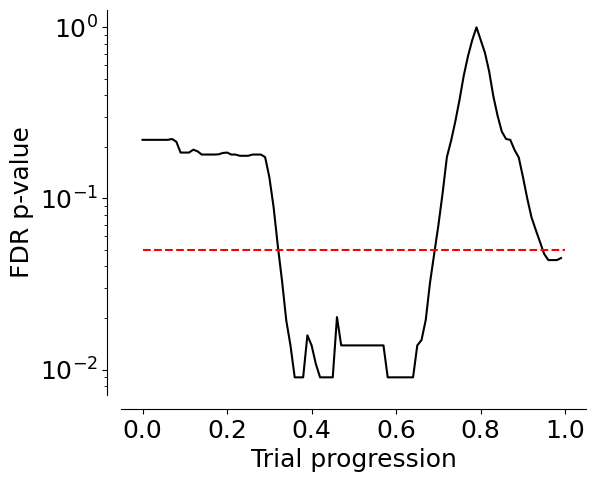

In [14]:
agg = (
    interpolated_df
    .groupby(["dataset", "aperture", "trial_length"], as_index=False)[
        ["heading_dir_flipped", "head_angle_flipped"]
    ]
    .mean(numeric_only=True)
)

aperture_order = sorted(agg.aperture.unique())

p_values = []
for tl in sorted(agg.trial_length.unique()):
    section = agg[agg.trial_length == tl]
    t = ttest_ind(
        section[section.aperture == aperture_order[0]].heading_dir_flipped,
        section[section.aperture == aperture_order[1]].heading_dir_flipped,
    )
    p_values.append({"segment": tl, "p_value": t.pvalue})

p_value_df = pd.DataFrame(p_values)
p_value_df["p_value_corr"] = stats.false_discovery_control(p_value_df.p_value)

fig, ax = plt.subplots(1, 1, figsize=(6, 5))
plt.plot(p_value_df.segment, p_value_df.p_value_corr, c="k")

plt.hlines(0.05, xmin=0, xmax=1, color="red", linestyle="dashed")

plt.xlabel("Trial progression")
plt.ylabel("FDR p-value")
plt.yscale("log")

sns.despine(offset=10)
plt.savefig(save_fig_path + "figure4_heading_dir_p_values.svg", bbox_inches="tight", transparent=True)

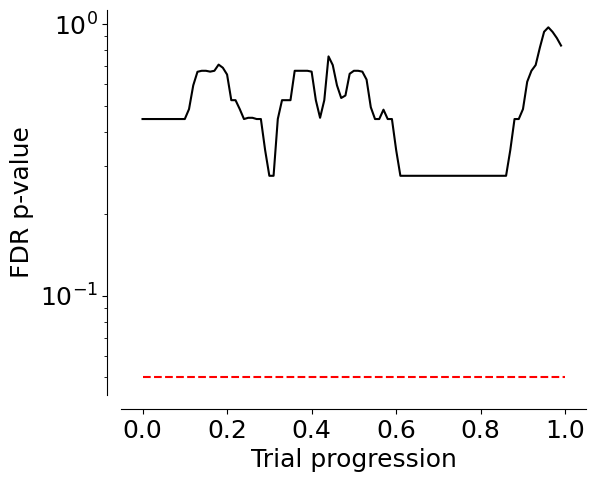

In [15]:
aperture_order = sorted(agg.aperture.unique())
p_values = []
for tl in sorted(agg.trial_length.unique()):
    section = agg[agg.trial_length == tl]
    t = ttest_ind(
        section[section.aperture == aperture_order[0]].head_angle_flipped,
        section[section.aperture == aperture_order[1]].head_angle_flipped,
    )
    p_values.append({"segment": tl, "p_value": t.pvalue})

p_value_df = pd.DataFrame(p_values)
p_value_df["p_value_corr"] = stats.false_discovery_control(p_value_df.p_value)

fig, ax = plt.subplots(1, 1, figsize=(6, 5))
plt.plot(p_value_df.segment, p_value_df.p_value_corr, c="k")

plt.hlines(0.05, xmin=0, xmax=1, color="red", linestyle="dashed")

plt.xlabel("Trial progression")
plt.ylabel("FDR p-value")
plt.yscale("log")

sns.despine(offset=10)
plt.savefig(save_fig_path + "figure4_head_angle_p_values.svg", bbox_inches="tight", transparent=True)

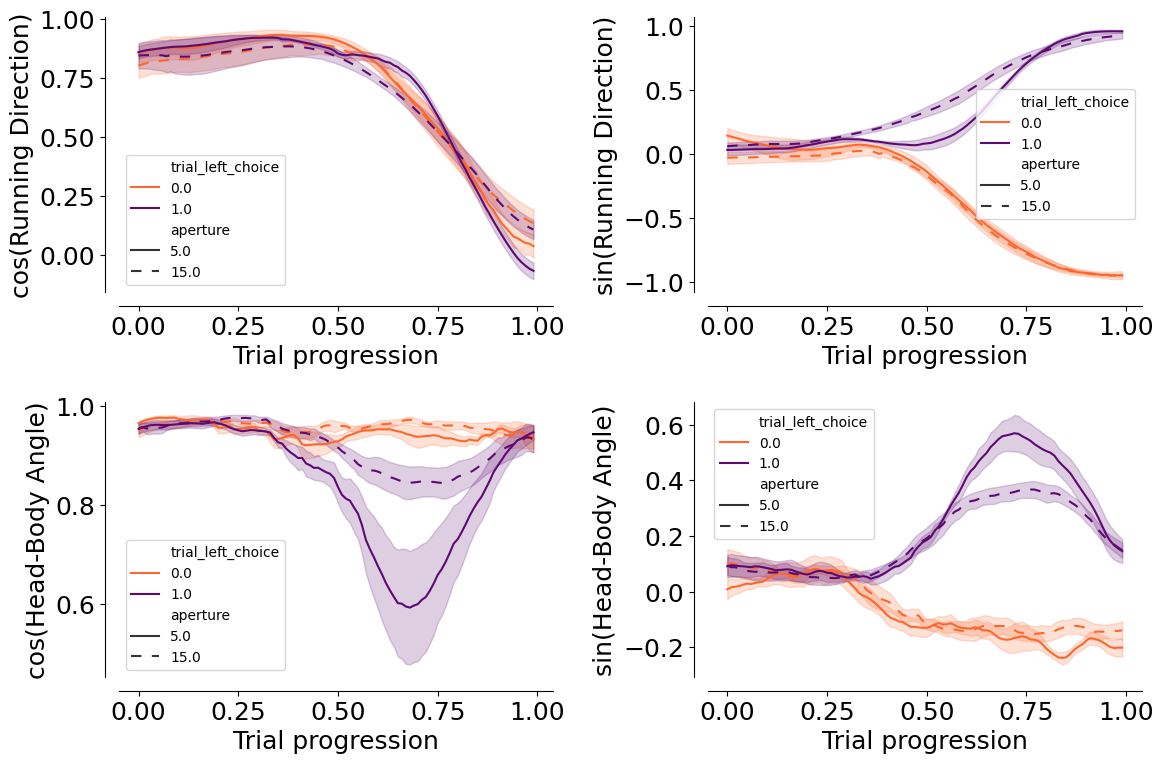

In [16]:
mean_mouse = interpolated_df.groupby(
    ["dataset", "aperture", "trial_left_choice", "trial_length"], as_index=False
).mean(numeric_only=True)

fig, ax = plt.subplots(2, 2, figsize=(12, 8))
ax = ax.flatten()

dash_styles = {
    mean_mouse.aperture.unique()[0]: "",         # Solid
    mean_mouse.aperture.unique()[1]: (5, 5)      # Dashed
}

for (i, label), label_str in zip(enumerate(
    ["heading_dir_cos", "heading_dir_sin", "head_angle_cos", "head_angle_sin"]
), ["cos(Running Direction)", "sin(Running Direction)", "cos(Head-Body Angle)", "sin(Head-Body Angle)"]):
    sns.lineplot(
        data=mean_mouse,
        x="trial_length",
        y=label,
        palette=plotting.colors_choice[::-1]
        if len(mean_mouse.aperture.unique()) == 2
        else "viridis",
        hue="trial_left_choice"
        if len(mean_mouse.aperture.unique()) == 2
        else "aperture",
        style=(
            "aperture"
            if len(mean_mouse.aperture.unique()) == 2
            else "trial_left_choice"
        ),
        dashes=dash_styles,
        errorbar="se",
        ax=ax[i],
    )
    ax[i].set_ylabel(label_str)
    ax[i].set_xlabel("Trial progression")
    sns.despine(ax=ax[i], offset=10)


plt.tight_layout(pad=2)
plt.savefig(save_fig_path + "figure4_heading_dir_head_angle_cos_sin.svg", bbox_inches="tight", transparent=True)

## Prediction model

In [17]:
model_key = {"label_set_id": 8, "params_id": 1}

/tmp/ipykernel_77212/2790331071.py:1: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  coefs = (PredictionModel10Windows() & task_type_key & model_key).fetch("coefficients_by_window")[0]
/tmp/ipykernel_77212/2790331071.py:2: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  model_labels, clean_labels = (LabelSet.Member * Label & model_key).fetch("label_key", "clean_name")


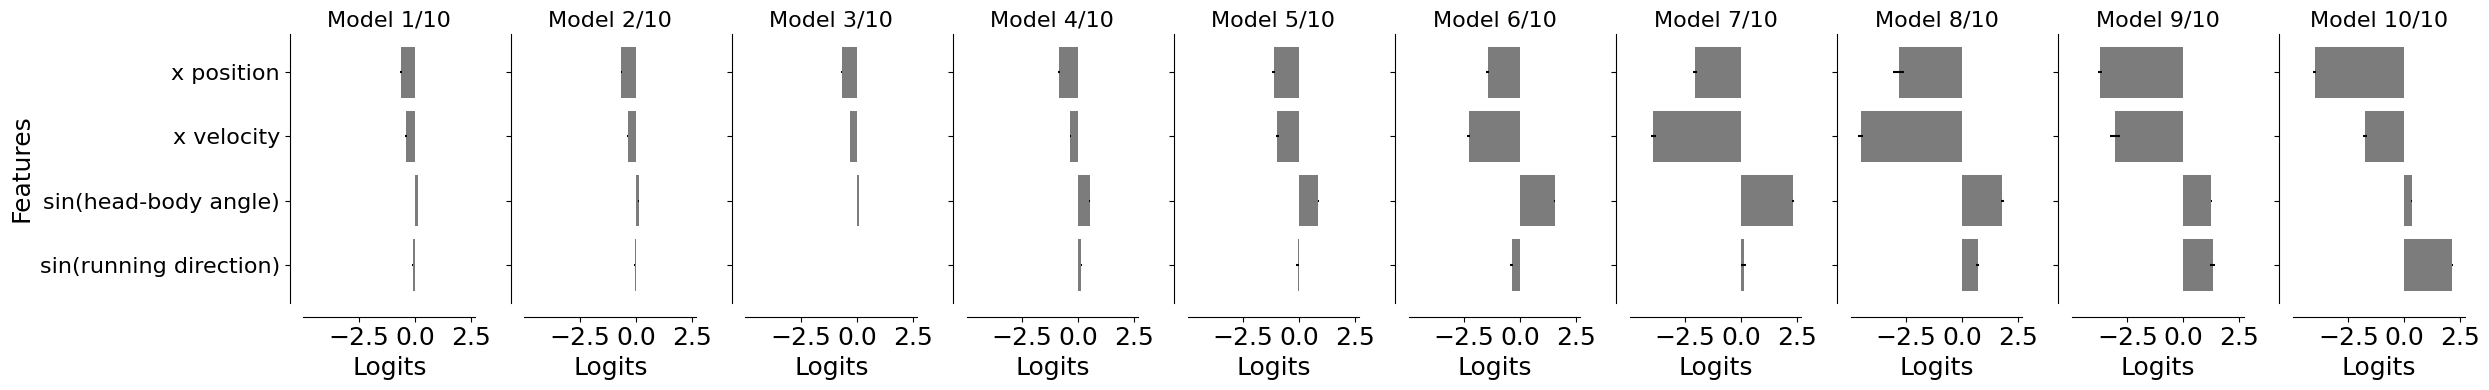

In [18]:
coefs = (PredictionModel10Windows() & task_type_key & model_key).fetch("coefficients_by_window")[0]
model_labels, clean_labels = (LabelSet.Member * Label & model_key).fetch("label_key", "clean_name")

fig, ax = plt.subplots(1, 10, figsize=(25, 4), sharey=True, sharex=True)
ax = ax.flatten()
for axis, key in zip(ax, coefs.keys()):
    
    axis.barh(
        model_labels,
        np.mean(coefs[key][:, 1:], axis=0),
        xerr=stats.sem(coefs[key][:, 1:], axis=0),
        color="#7C7C7C",
    )
    sns.despine(offset=10, ax=axis)

    axis.set_yticks(np.arange(len(model_labels)))
    axis.set_yticklabels(clean_labels, rotation=0, ha="right", fontsize=16)
    axis.set_xlabel("Logits")
    if key == 0:
        axis.set_ylabel("Features")
    else:
        axis.set_ylabel("")
    axis.set_title(f"Model {key+1}/10", fontsize=16)
plt.tight_layout()
plt.savefig(save_fig_path + "figure4_models_logits.svg", transparent=True, bbox_inches="tight")

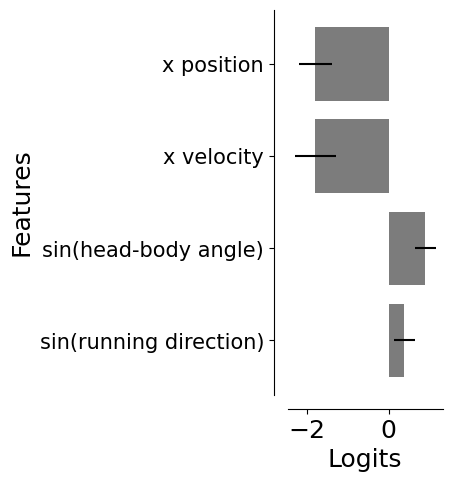

In [19]:
# Average across windows
mean_coef = np.array([np.mean(coefs[key], axis=0) for key in coefs.keys()])

fig, ax = plt.subplots(1, 1, figsize=(2, 5))
ax.barh(
    model_labels,
    np.mean(mean_coef[:, 1:], axis=0),
    xerr=stats.sem(mean_coef[:, 1:], axis=0), # sem across windows
    color="#7C7C7C",
)
sns.despine(offset=10, ax=ax)

ax.set_yticks(np.arange(len(model_labels)))
ax.set_yticklabels(clean_labels, rotation=0, ha="right", fontsize=15)
ax.set_xlabel("Logits")
ax.set_ylabel("Features")

plt.savefig(save_fig_path + "figure4_avg_model_logits.svg", transparent=True, bbox_inches="tight")

In [129]:
prediction_df = pd.DataFrame((PredictionModel10Windows().SessionPrediction() & model_key & task_type_key & {"batch_name": "batch1"}).fetch(
    "dataset", "trial", "proba_left", "accuracy", "trial_length", as_dict=True)).explode(["trial", "proba_left", "accuracy", "trial_length"])

/tmp/ipykernel_77212/198590891.py:1: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  prediction_df = pd.DataFrame((PredictionModel10Windows().SessionPrediction() & model_key & task_type_key & {"batch_name": "batch1"}).fetch(


In [130]:
df_model = prediction_df.merge(
    interpolated_df[["dataset", "trial_length", "trial", "aperture", "trial_left_choice", "x", "y"]], on=["dataset", "trial", "trial_length"]
)

df_model["accuracy"] = df_model["accuracy"].astype(float)
df_model["proba_left"] = df_model["proba_left"].astype(float)

In [131]:
# Get the rate of left vs right choices per dataset
n_trial_per_aperture = df_model.groupby(["dataset","aperture","trial_left_choice"], as_index=False)["trial"].nunique()

df_rates = n_trial_per_aperture.pivot(
    index=["dataset", "aperture"], 
    columns="trial_left_choice", 
    values="trial"
).reset_index()

df_rates = df_rates.fillna(0)
df_rates.rename(columns={0.0: "right_count", 1.0: "left_count"}, inplace=True)

df_rates["total_trials"] = df_rates["left_count"] + df_rates["right_count"]
df_rates["left_rate"] = df_rates["left_count"] / df_rates["total_trials"]

epsilon = 1e-5
df_rates["logit_bias"] = np.log((df_rates["left_count"] + epsilon) / (df_rates["right_count"] + epsilon))
df_rates = df_rates.groupby("dataset").mean()

total_left = df_rates['left_count'].sum()
total_right = df_rates['right_count'].sum()

# Compute the "Leave-One-Out" behavioral logit for each dataset
# This is the prior the model 'sees' during training for that specific fold
df_rates['loso_behavioral_logit'] = df_rates.apply(
    lambda row: np.log((total_left - row['left_count']) / (total_right - row['right_count'])), 
    axis=1
)
df_rates.reset_index(inplace=True)

In [132]:
df_rates.left_rate.mean()

0.6536225266419307

In [133]:
n_trial_per_aperture = df_model.groupby(["dataset","aperture","trial_left_choice"], as_index=False)["trial"].nunique()

Rate of trials per condition:
trial_left_choice
0.0    0.360476
1.0    0.639524
Name: trial, dtype: float64


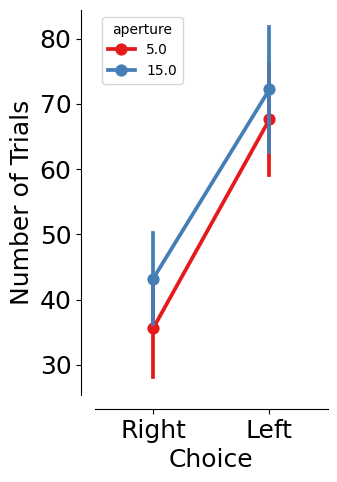

In [134]:
fig = plt.figure(figsize=(3, 5))
sns.pointplot(n_trial_per_aperture, x="trial_left_choice", y="trial",
              hue="aperture", palette=plotting.colors_aperture, errorbar="se")
plt.xlim(-0.5, 1.5)
plt.xlabel("Choice")
plt.ylabel("Number of Trials")
plt.xticks([0, 1], ["Right", "Left"])
print("Rate of trials per condition:")
print(n_trial_per_aperture.groupby("trial_left_choice")["trial"].sum()/n_trial_per_aperture["trial"].sum())

sns.despine(offset=10)

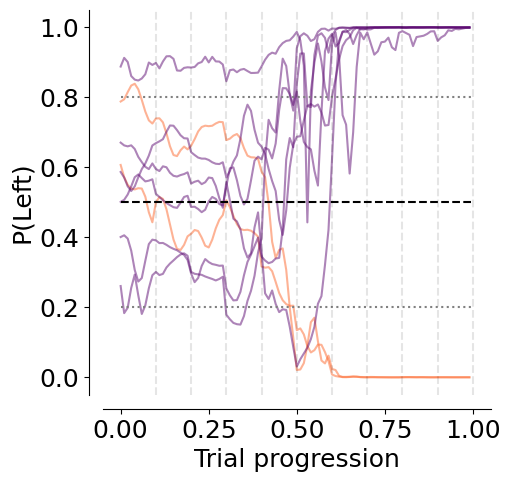

In [135]:
fig, ax = plt.subplots(1, 1, figsize=(5, 5))

group = df_model[(df_model.dataset == 'Uguisu_2024-09-23_1')]

trials = [
    94,
    15,
    66,
    170,
    224,
    195,
    56,
    203,
    88,
    239,
    113,
    91,
    186,
    248,
    109,
    164,
    188,
    60,
    229,
    182,
    156,
    197,
    52,
    45,
]

group = group[group.trial.isin(np.array(trials))]
sns.lineplot(
    data=group,
    x="trial_length",
    y="proba_left",
    hue="trial_left_choice",
    errorbar=None,
    estimator=None,
    units="trial",
    palette=plotting.colors_choice[::-1],
    sort=False,
    alpha=0.5,
    ax=ax,
)
ax.set_ylabel("P(Left)")
ax.set_xlabel("Trial progression")
ax.hlines(0.5, xmin=0, xmax=1, colors="black", linestyles="dashed")
ax.hlines(0.8, xmin=0, xmax=1, colors="gray", linestyles="dotted")
ax.hlines(0.2, xmin=0, xmax=1, colors="gray", linestyles="dotted")
ax.legend([], [], frameon=False)

for i in range(10):
    plt.axvline((i+1)/10, color="k", linestyle="dashed", alpha=0.1)

sns.despine(offset=10)

plt.savefig(
    save_fig_path + "figure4_dynamic_decision_variable.png",
    transparent=True, bbox_inches="tight", dpi=300
)

plt.savefig(
    save_fig_path + "figure4_dynamic_decision_variable.svg",
    transparent=True, bbox_inches="tight"
)

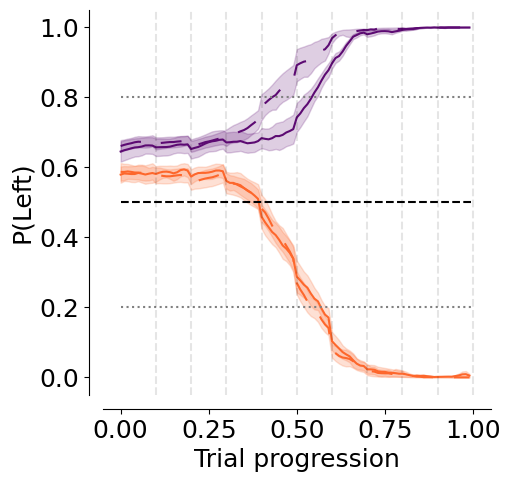

In [136]:
df_model_mean =  df_model.groupby(["dataset", "aperture", "trial_left_choice", "trial_length"], as_index=False).mean(numeric_only=True)
fig, ax = plt.subplots(1, 1, figsize=(5, 5))

dash_styles = {
    mean_mouse.aperture.unique()[0]: "",         # Solid
    mean_mouse.aperture.unique()[1]: (10, 10)      # Dashed
}

sns.lineplot(
    data=df_model_mean,
    x="trial_length",
    y="proba_left",
    hue="trial_left_choice",
    style="aperture",
    palette=plotting.colors_choice[::-1],
    sort=False,
    alpha=1,
    ax=ax,
    errorbar="se",
    dashes=dash_styles
)
ax.set_ylabel("P(Left)")
ax.set_xlabel("Trial progression")

ax.hlines(0.5, xmin=0, xmax=1, colors="black", linestyles="dashed")
ax.hlines(0.8, xmin=0, xmax=1, colors="gray", linestyles="dotted")
ax.hlines(0.2, xmin=0, xmax=1, colors="gray", linestyles="dotted")
ax.legend([], [], frameon=False)
sns.despine(offset=10)

for i in range(10):
    plt.axvline((i+1)/10, color="k", linestyle="dashed", alpha=0.1)
    

plt.savefig(
    save_fig_path + "figure4_dynamic_decision_variable_avg.png",
    transparent=True,
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    save_fig_path + "figure4_dynamic_decision_variable_avg.svg",
    transparent=True,
)

In [137]:
df_model_mean[df_model_mean.trial_length < 0.01].proba_left.mean()

0.6180843729388302

In [138]:
# Build t=0 feature table (one row per trial start)
t0_mask = np.isclose(interpolated_df["trial_length"].astype(float), 0.0)
features_t0 = (
    interpolated_df.loc[t0_mask, ["x", "velocity_x_fliped", "head_angle_sin", "heading_dir_sin"]]
    .rename(
        columns={
            "x": "x position",
            "velocity_x_fliped": "x velocity",
            "head_angle_sin": "sin(head-body angle)",
            "heading_dir_sin": "sin(running direction)",
        }
    )
    .dropna()
)

# Model weights (window 0)
intercept = float(np.mean(coefs[0][:, 0]))
feature_weights = {
    "x position": float(np.mean(coefs[0][:, 1])),
    "x velocity": float(np.mean(coefs[0][:, 2])),
    "sin(head-body angle)": float(np.mean(coefs[0][:, 3])),
    "sin(running direction)": float(np.mean(coefs[0][:, 4])),
}

# Feature contributions at t=0
contributions = {
    feature: features_t0[feature].mean() * weight
    for feature, weight in feature_weights.items()
}

df_bias = pd.DataFrame.from_dict(contributions, orient="index", columns=["Logit_Contribution"])
df_bias.loc["Intercept"] = intercept
df_bias["Absolute_Impact"] = df_bias["Logit_Contribution"].abs()
df_bias = df_bias.sort_values(by="Absolute_Impact", ascending=False)

print("Bias Decomposition at t=0:")
print(df_bias)

total_logit = df_bias["Logit_Contribution"].sum()
starting_prob = 1 / (1 + np.exp(-total_logit))
print(f"\nTotal Logit: {total_logit:.4f}")
print(f"Starting Probability: {starting_prob:.4f}")

Bias Decomposition at t=0:
                        Logit_Contribution  Absolute_Impact
Intercept                         0.636036         0.636036
x velocity                        0.154862         0.154862
x position                       -0.076383         0.076383
sin(running direction)           -0.035191         0.035191
sin(head-body angle)             -0.027377         0.027377

Total Logit: 0.6519
Starting Probability: 0.6574


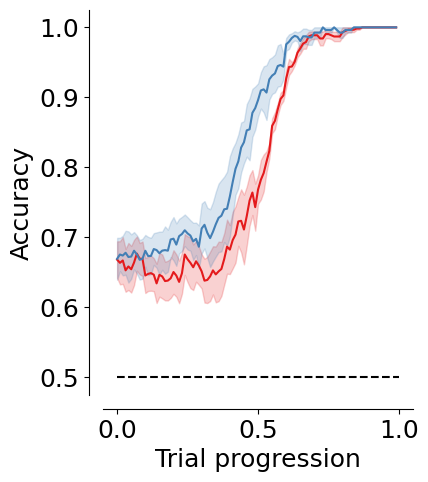

In [139]:
df_model_mean =  df_model.groupby(["dataset", "aperture", "trial_length"], as_index=False).mean(numeric_only=True)

fig, ax = plt.subplots(1, 1, figsize=(4, 5))
sns.lineplot(
    data=df_model_mean,
    x="trial_length",
    y="accuracy",
    hue="aperture",
    palette=plotting.colors_aperture,
    sort=False,
    alpha=1,
    ax=ax,
    errorbar="se"
)
ax.hlines(0.5, 0, 1, color="black", linestyle="--")

ax.set_ylabel("Accuracy")
ax.set_xlabel("Trial progression")
ax.legend([], [], frameon=False)
sns.despine(offset=10)

plt.savefig(
    save_fig_path + "figure4_model_accuracy.svg", transparent=True
)

In [140]:
df_model["trial_length_bin"] = pd.cut(
    df_model["trial_length"], bins=50
)

df_anova = df_model.groupby(
    ["dataset", "aperture", "trial_length_bin"], as_index=False
)["accuracy"].mean()

print(
    AnovaRM(
        data=df_anova,
        depvar="accuracy",
        subject="dataset",
        within=["aperture", "trial_length_bin"],
    ).fit()
)

                          Anova
                          F Value  Num DF  Den DF  Pr > F
---------------------------------------------------------
aperture                   5.1979  1.0000   4.0000 0.0848
trial_length_bin          94.5456 49.0000 196.0000 0.0000
aperture:trial_length_bin  3.8399 49.0000 196.0000 0.0000



/opt/conda/lib/python3.11/site-packages/scipy/stats/_axis_nan_policy.py:586: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)


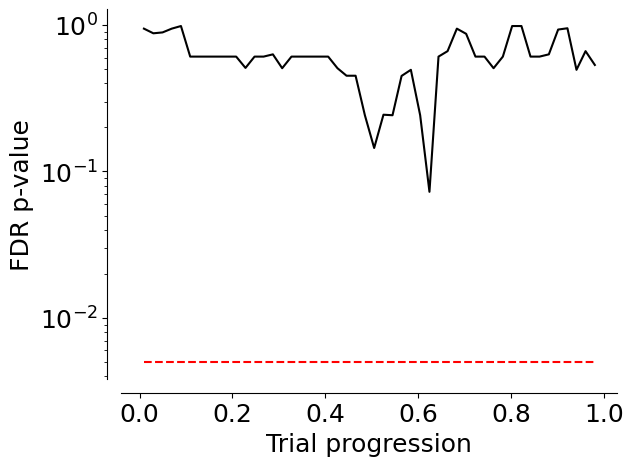

In [141]:
p_values = []
for i in df_anova.trial_length_bin.unique():
    section = df_anova[df_anova.trial_length_bin == i]
    t = ttest_ind(
        section[section.aperture == section.aperture.unique()[0]].accuracy,
        section[section.aperture == section.aperture.unique()[1]].accuracy + np.random.normal(0, 1e-5, size=section[section.aperture == section.aperture.unique()[1]].accuracy.shape)
    )
    p_values.append(pd.DataFrame({"segment": i, "p_value": t.pvalue}, index=[0]))

p_value_df = pd.concat(p_values)
p_value_df["p_value_corr"] = stats.false_discovery_control(p_value_df.p_value)

# Convert interval bins to numeric midpoints
p_value_df["segment"] = p_value_df["segment"].apply(lambda x: x.mid)

plt.plot(p_value_df.segment, p_value_df.p_value_corr, c="k")

plt.hlines(
    0.005,
    xmin=p_value_df.segment.min(),
    xmax=p_value_df.segment.max(),
    color="red",
    linestyle="dashed",
)

plt.xlabel("Trial progression")
plt.ylabel("FDR p-value")
plt.yscale("log")

sns.despine(offset=10)
plt.savefig(
    save_fig_path + "figure4_model_accuracy_pvalue.svg", transparent=True
)

In [142]:
p_value_df

,segment,p_value,p_value_corr
0,0.009405,0.869143,0.944721
0,0.029700,0.719851,0.877867
0,0.049500,0.747826,0.890269
0,0.069300,0.843046,0.944721
0,0.089100,0.984209,0.984209
0,0.109000,0.408307,0.608593
0,0.129000,0.392564,0.608593
0,0.148500,0.356245,0.608593
0,0.168000,0.366516,0.608593
0,0.188000,0.247204,0.608593


## Decision point analysis

### Select the threshold based on change in kinematics

In [143]:
session_to_plot = 'Uguisu_2024-09-23_1'

In [144]:
threshold_values = [0.1, 0.2, 0.3, 0.4, 0.5]
threshold_keys = [{'threshold_uncertainty': val} for val in threshold_values]

In [145]:
all_decision_points = pd.DataFrame((DecisionPoints10Windows() & task_type_key & model_key & {"batch_name": "batch1"}).fetch(as_dict=True))
all_decision_points = all_decision_points.explode(["trial", "aperture", "trial_length", "trial_left_choice", "proba_left", "x", "y", "trial_rewarded"])
all_decision_points["mouse_name"] = all_decision_points.dataset.str.split("_").str[0]

/tmp/ipykernel_77212/2170161695.py:1: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  all_decision_points = pd.DataFrame((DecisionPoints10Windows() & task_type_key & model_key & {"batch_name": "batch1"}).fetch(as_dict=True))


In [146]:
all_decision_points.dropna(subset=["y"], inplace=True)
all_decision_points["distance_to_screen"] = np.abs(all_decision_points["y"] - 27)

In [147]:
# Compare metrics before vs after to select the best threshold for defining decision points
decision_window = 10
eval_df_norm = regression.select_threshold(all_decision_points, interpolated_df, decision_window=decision_window)

Analyzing decision points with threshold_uncertainty 0.5 (normalized)...
Analyzing decision points with threshold_uncertainty 0.4 (normalized)...
Analyzing decision points with threshold_uncertainty 0.3 (normalized)...
Analyzing decision points with threshold_uncertainty 0.2 (normalized)...
Analyzing decision points with threshold_uncertainty 0.1 (normalized)...


In [148]:
mean_eval_df_norm = eval_df_norm.groupby("threshold", as_index=False).mean(numeric_only=True)

In [149]:
mean_eval_df_norm

,threshold,jump_score_norm,jump_score,n_trials,z_vx,z_vy,z_ang,z_dir,vx_delta,vy_delta,ang_delta,dir_delta,t_stat,p_value,p_value_fisher,z_vx_minmax,z_vy_minmax,z_ang_minmax,z_dir_minmax,jump_score_norm_minmax
0,0.1,2.104540,63.982094,217.2,0.957995,-0.295334,0.479943,0.371270,14.756548,-7.567224,21.008803,20.649519,9.694661,1.279556e-13,6.173532e-90,0.665892,0.249850,0.539949,0.866252,1.822243
1,0.2,1.896599,61.044820,214.4,0.923578,-0.269863,0.446600,0.256557,14.361803,-7.360419,20.120199,19.202400,8.536114,7.699967e-11,9.268997e-72,0.630346,0.303339,0.478347,0.712461,1.517815
2,0.3,1.629607,57.782549,205.6,0.843616,-0.205861,0.452572,0.127558,13.457775,-6.661862,20.173989,17.488923,6.961849,2.738800e-08,1.938612e-48,0.547760,0.437749,0.489381,0.539516,1.138908
3,0.4,1.267364,53.395740,195.8,0.686513,-0.154074,0.411500,0.015277,11.664840,-6.126046,19.585513,16.019340,5.126253,3.432783e-06,3.797943e-26,0.385502,0.546505,0.413496,0.388985,0.641478
4,0.5,1.022070,50.277993,185.8,0.564632,-0.110798,0.400158,-0.053518,10.281432,-5.550844,19.309636,15.136080,4.001485,2.562504e-04,5.169456e-16,0.259622,0.637389,0.392542,0.296753,0.311528


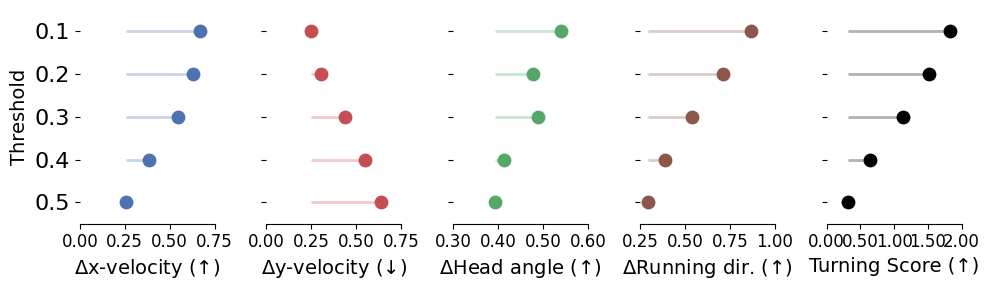

In [150]:
plot_df = mean_eval_df_norm.sort_values("jump_score_norm", ascending=True)

fig, axes = plt.subplots(1, 5, figsize=(10, 3), sharey=True)
metrics = ["z_vx", "z_vy", "z_ang", "z_dir", "jump_score_norm"]
metrics_standardized = [f"{metric}_minmax" for metric in metrics]
titles = ["$\Delta$x-velocity (↑)", "$\Delta$y-velocity (↓)", "$\Delta$Head angle (↑)", "$\Delta$Running dir. (↑)", "Turning Score (↑)"]
colors = ["#4C72B0", "#C44E52", "#55A868", "#8C564B", "black"]

for i, (ax, col, title, color) in enumerate(zip(axes, metrics_standardized, titles, colors)):
    # Plot dots
    ax.scatter(plot_df[col], plot_df["threshold"], color=color, s=80, zorder=3)
    # Add horizontal lines for readability
    ax.hlines(y=plot_df["threshold"], xmin=plot_df[col].min(), xmax=plot_df[col], 
              color=color, alpha=0.3, linewidth=2)
    
    ax.set_xlabel(title, fontsize=14)
    ax.set_yticks(plot_df["threshold"])
    ax.set_yticklabels(plot_df["threshold"], fontsize=16)
    
    # Get the existing x-axis ticks and just chage the size
    ticks = ax.get_xticks()
    ax.set_xticks(ticks, minor=False)
    ax.set_xticklabels([f"{tick:.2f}" for tick in ticks], fontsize=12)
    ax.set_ylim(-0.5, 4.5)

axes[0].set_ylabel("Threshold", fontsize=14)

plt.tight_layout()
sns.despine(left=True, bottom=False)
plt.savefig(save_fig_path + "figure4_decision_point_threshold_comparison.svg", transparent=True, bbox_inches="tight")

### Threshold selected: 0.1 [CHANGED], the rest is with that threshold

In [43]:
decision_points = pd.DataFrame((DecisionPoints10Windows() & task_type_key & model_key & "threshold_uncertainty = 0.1").fetch(as_dict=True))
decision_points = decision_points.explode(["trial", "aperture", "trial_length", "trial_left_choice", "proba_left", "x", "y", "trial_rewarded"])
decision_points["mouse_name"] = decision_points.dataset.str.split("_").str[0]

/tmp/ipykernel_77212/713746670.py:1: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  decision_points = pd.DataFrame((DecisionPoints10Windows() & task_type_key & model_key & "threshold_uncertainty = 0.1").fetch(as_dict=True))


In [44]:
decision_points["distance_to_screen"] = np.abs(decision_points["y"].astype(float) - 27)

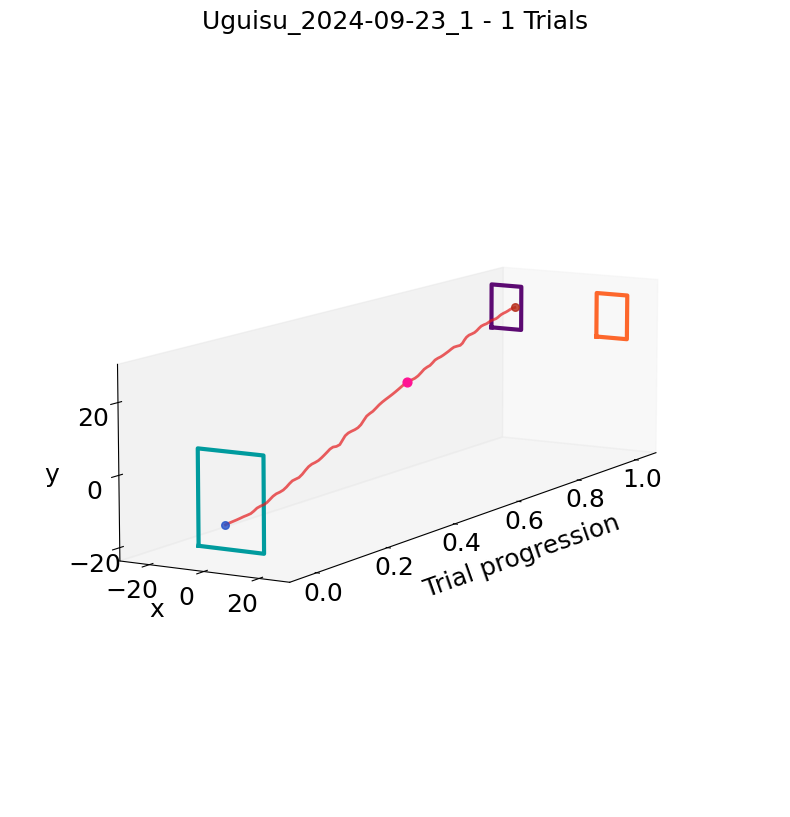

<Figure size 640x480 with 0 Axes>

In [45]:
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111, projection='3d')

ax = plotting.plot_session_3d(
    df=interpolated_df[interpolated_df.dataset == session_to_plot],
    box_df=box_df,
    trial_ids=[69],
    ax=ax,
    color_by_aperture=True,
    color_by_choice=False,
    decision_points=decision_points[decision_points.dataset == session_to_plot]
)

plt.show()
plt.savefig(save_fig_path + "figure4_3d_trajectory_wide.svg", bbox_inches="tight", transparent=True)

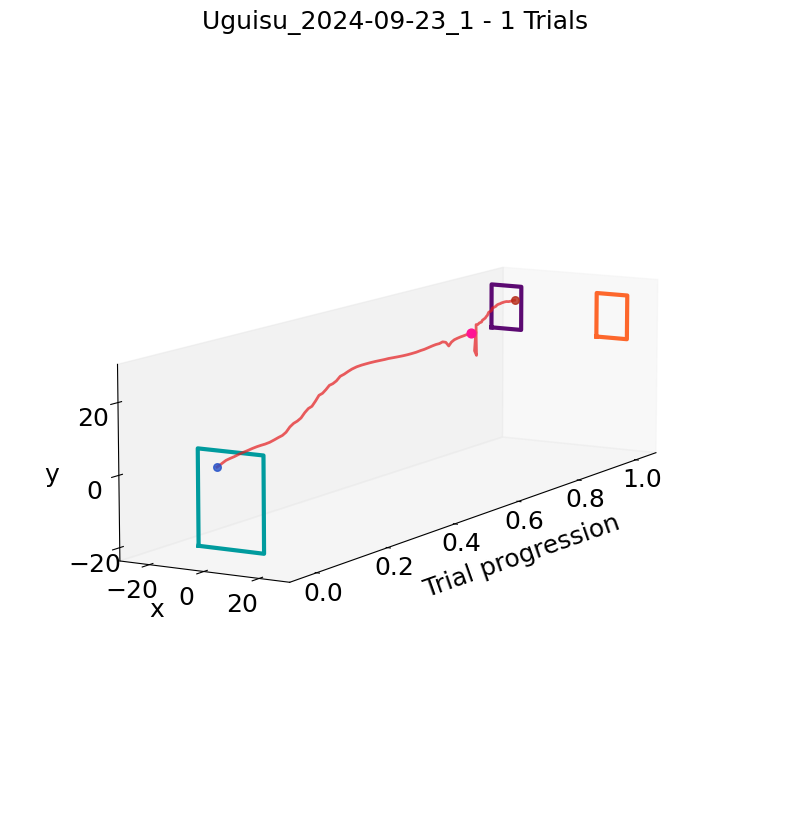

<Figure size 640x480 with 0 Axes>

In [46]:
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111, projection='3d')

ax = plotting.plot_session_3d(
    df=interpolated_df[interpolated_df.dataset == session_to_plot],
    box_df=box_df,
    trial_ids=[40],
    ax=ax,
    color_by_aperture=True,
    color_by_choice=False,
    decision_points=decision_points[decision_points.dataset == session_to_plot]
)

plt.show()
plt.savefig(save_fig_path + "figure4_3d_trajectory_narrow.svg", bbox_inches="tight", transparent=True)

In [52]:
with open("information_maps/shape_info_maps/info_matrix_unnormalized_14.5222w.npy", "rb") as file:
    info_matrix_narrow = np.rot90(np.load(file), k=1)
with open("information_maps/shape_info_maps/info_matrix_unnormalized_43.208w.npy", "rb") as file:
    info_matrix_wide = np.rot90(np.load(file), k=1)

info_matrices = [info_matrix_narrow, info_matrix_wide]

# normalize across both maps to max 1
max_value = max(im.max() for im in info_matrices)
info_matrices = [im / max_value for im in info_matrices]

/tmp/ipykernel_77212/154283661.py:26: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  base_cmap = cm.get_cmap("PuOr")


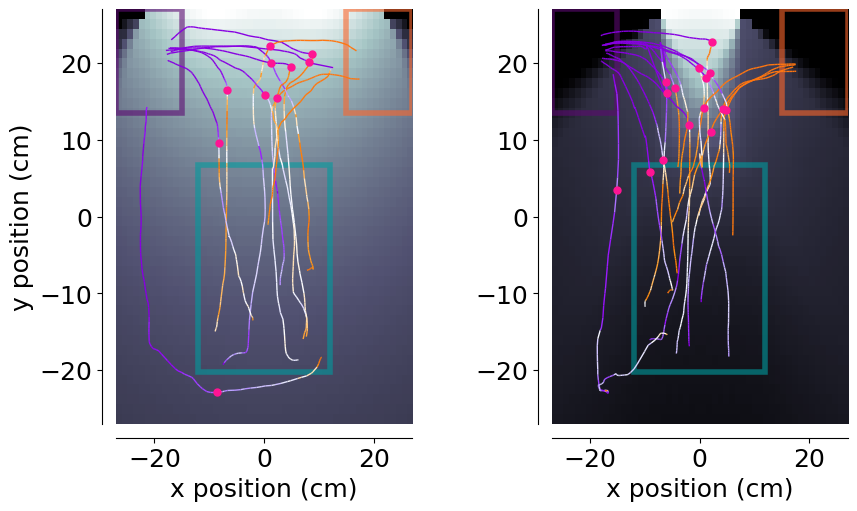

In [53]:
fig, ax = plt.subplots(
    1, len(df_model.aperture.unique()), figsize=(9, 5), constrained_layout=True
)

decision_color = "deeppink"
session_to_plot = 'Uguisu_2024-09-23_1'

trials = [44, 45, 19, 62, 61, 45, 85, 41, 43, 41, 50, 75, 24, 69, 84, 74, 10] + [
    63,
    30,
    78,
    47,
    33,
    5,
    17,
    9,
    47,
    30,
    99,
    11,
    12,
    15,
]

# Start from PuOr
base_cmap = cm.get_cmap("PuOr")

# Make a brighter version by rescaling luminance
def brighten(cmap, factor=3):
    colors = cmap(np.linspace(0, 1, 256))
    rgb = mcolors.rgb_to_hsv(colors[:, :3])
    rgb[:, 2] = rgb[:, 2] * factor  # brighten value channel
    rgb[:, 2] = np.clip(rgb[:, 2], 0, 1)
    colors[:, :3] = mcolors.hsv_to_rgb(rgb)
    return mcolors.ListedColormap(colors)

bright_puor = brighten(base_cmap)

for i, aperture in enumerate(df_model.aperture.unique()):
    regression.plot_decision_points_on_trajectory(
        df_model[
            (df_model.dataset == session_to_plot) & (df_model.aperture == aperture)
        ],
        box_df,
        decision_point=decision_points[
            (decision_points.dataset == session_to_plot)
            & (decision_points.aperture == aperture)
        ],
        color=decision_color,
        trials=trials,
        ax=ax[i],
        cmap=bright_puor,
    )

    im = ax[i].imshow(info_matrices[::-1][i], 
                 cmap="bone", 
                 extent=[-27, 27, -27, 27],
                 zorder=-10)
    
    ax[i].set_xlim(-27, 27)
    ax[i].set_ylim(-27, 27)
    ax[i].set_aspect(1.4)
    ax[i].set_xlabel("x position (cm)")
    sns.despine(offset=10, ax=ax[i])
    

ax[0].set_ylabel("y position (cm)")
ax[1].set_ylabel("")

plt.savefig(
    save_fig_path + "figure4_decision_points_trajectories_bright.svg",
    transparent=True,
)

### Velocity aligned on the decision point

In [54]:
def get_info_at_position(info_matrix, position):
    # Assuming info_matrix is a 2D numpy array and position is a tuple (x, y)
    x, y = position
    # Convert position to matrix indices
    x_idx = int(x + 27)
    y_idx = int(y + 27)
    
    # but the matrix is 52x42 so the positions need to be scaled down
    x_idx_norm = int(x_idx * (51 / 54))
    y_idx_norm = int(y_idx * (41 / 54))
    
    y_idx_norm = info_matrix.shape[0] - 1 - y_idx_norm
    return info_matrix[y_idx_norm, x_idx_norm]  # Note: y comes first in matrix indexing

In [55]:
# Compute information for each timepoint in interpolated_df
interpolated_df["info_gain"] = interpolated_df.apply(
    lambda row: get_info_at_position(
        info_matrices[0] if row.aperture == 4.3 else info_matrices[1],
        (row.x, row.y),
    ),
    axis=1,
)

In [56]:
decision_points.dropna(subset=["x", "y"], inplace=True)
decision_points["info_gain"] = decision_points.apply(
    lambda row: get_info_at_position(
        info_matrices[0] if row.aperture == 4.3 else info_matrices[1],
        (row.x, row.y),
    ),
    axis=1,
)

In [57]:
# Convert to sec
interpolated_df["time_in_sec"] = interpolated_df["trial_length"] * interpolated_df["trial_duration"]

durations = interpolated_df[["dataset", "trial", "trial_duration"]].drop_duplicates()
decision_points = decision_points.merge(durations, on=["dataset", "trial"], how="left")
decision_points["time_in_sec"] = decision_points["trial_length"] * decision_points["trial_duration"]

In [58]:
interpolated_df["distance_to_screen"] = np.abs(interpolated_df["y"] - 27)

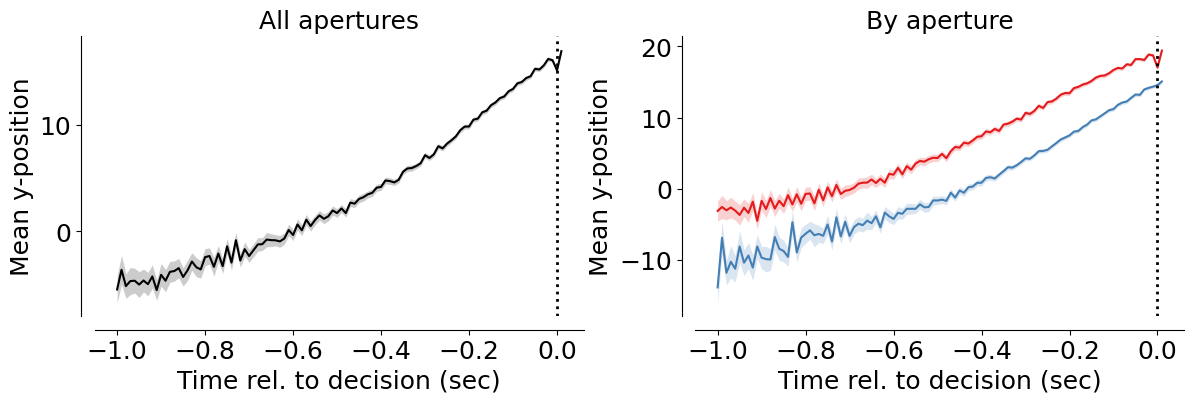

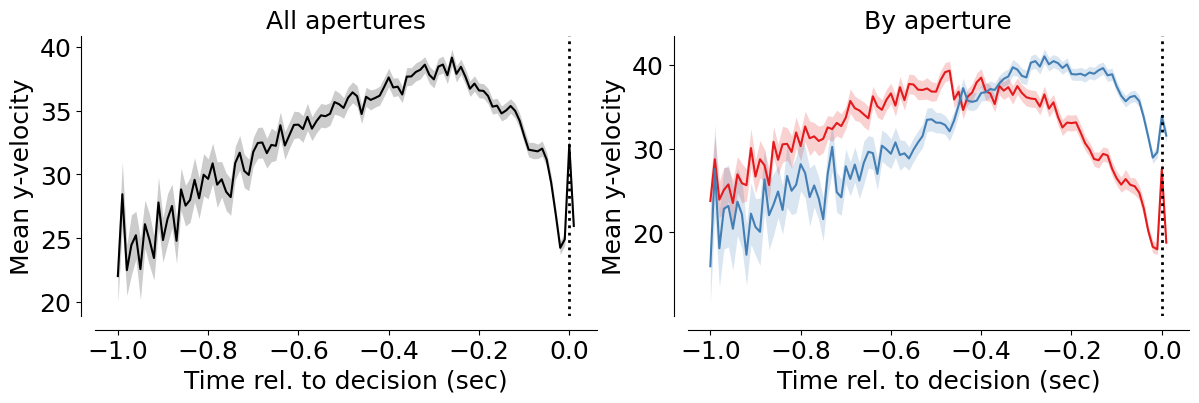

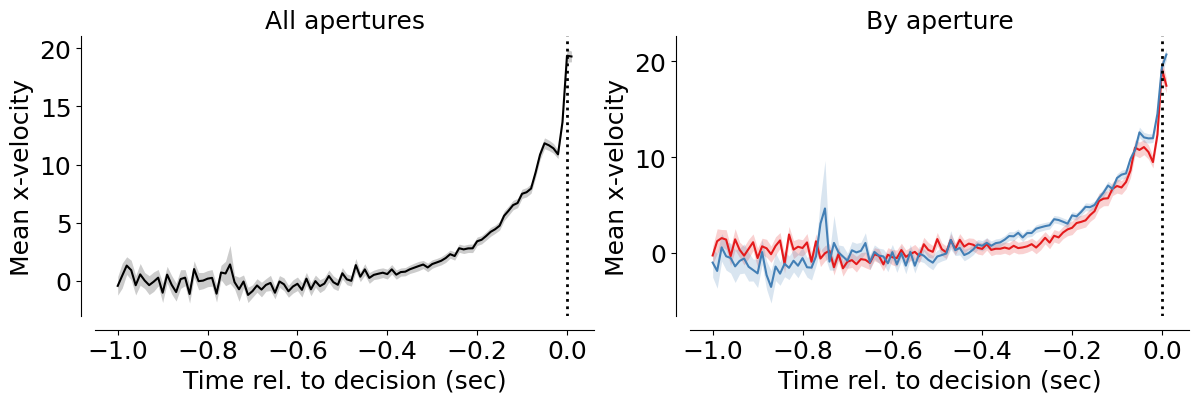

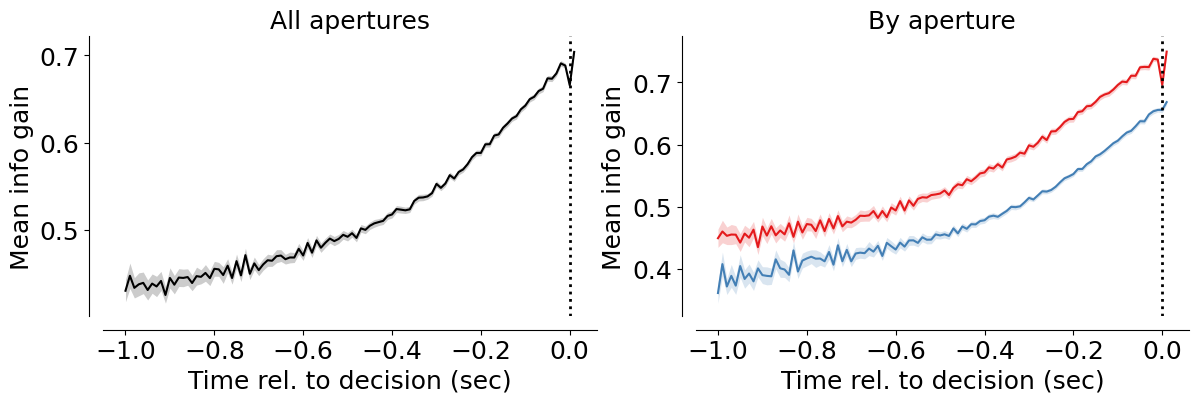

In [59]:
# Average velocity/info_gain around decision point
bin_size = 0.01
pre_window = 1.0
post_window = 0.02

dp_all = decision_points[["dataset", "aperture", "trial", "time_in_sec"]].rename(
    columns={"time_in_sec": "decision_tl"}
)

df_all = interpolated_df.merge(
    dp_all,
    on=["dataset", "aperture", "trial"],
    how="inner",
).copy()

df_all["t_rel"] = df_all["time_in_sec"] - df_all["decision_tl"]
df_all = df_all[(df_all.t_rel >= -pre_window) & (df_all.t_rel <= post_window)]

bins = np.arange(-pre_window, post_window + bin_size, bin_size)
df_all["t_bin"] = pd.cut(df_all.t_rel, bins=bins, labels=bins[:-1])

def _bin_mean_sem(frame, value_col):
    binned = (
        frame.groupby(["aperture", "t_bin"])[value_col]
        .agg(["mean", "sem"])
        .reset_index()
    )
    binned["t_bin"] = binned["t_bin"].astype(float)
    return binned

metrics = [
    {
        "col": "y",
        "ylabel": "Mean y-position",
        "file": "figure4_y_position_around_decision.svg",
    },
    {
        "col": "velocity_y",
        "ylabel": "Mean y-velocity",
        "file": "figure4_velocity_around_decision.svg",
    },
    {
        "col": "velocity_x_fliped",
        "ylabel": "Mean x-velocity",
        "file": "figure4_velocity_x_around_decision.svg",
    },
    {
        "col": "info_gain",
        "ylabel": "Mean info gain",
        "file": "figure4_info_gain_around_decision.svg",
    },
]

binned_by_metric = {}
for metric in metrics:
    value_col = metric["col"]
    binned = _bin_mean_sem(df_all, value_col)
    binned_by_metric[value_col] = binned
    
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)

    # Overall
    overall = (
        df_all.groupby("t_bin")[value_col]
        .agg(["mean", "sem"])
        .reset_index()
    )
    overall["t_bin"] = overall["t_bin"].astype(float)
    axes[0].plot(overall.t_bin, overall["mean"], color="black", linewidth=1.5)
    axes[0].fill_between(
        overall.t_bin,
        overall["mean"] - overall["sem"],
        overall["mean"] + overall["sem"],
        color="black",
        alpha=0.2,
        linewidth=0,
    )
    axes[0].axvline(0, color="black", linestyle=":", linewidth=2)
    axes[0].set_title("All apertures")
    axes[0].set_ylabel(metric["ylabel"])
    axes[0].set_xlabel("Time rel. to decision (sec)")
    sns.despine(ax=axes[0])

    # By aperture
    for idx, ap in enumerate(sorted(df_all.aperture.unique())[:2]):
        ap_df = binned[binned.aperture == ap]
        color = plotting.colors_aperture[idx] if "plotting" in globals() else None
        axes[1].plot(ap_df.t_bin, ap_df["mean"], color=color, linewidth=1.5, label=f"Aperture {ap}")
        axes[1].fill_between(
            ap_df.t_bin,
            ap_df["mean"] - ap_df["sem"],
            ap_df["mean"] + ap_df["sem"],
            color=color,
            alpha=0.2,
            linewidth=0,
        )
    axes[1].axvline(0, color="black", linestyle=":", linewidth=2)
    axes[1].set_title("By aperture")
    axes[1].set_xlabel("Time rel. to decision (sec)")
    axes[1].set_ylabel(metric["ylabel"])
    sns.despine(ax=axes[1])

    plt.tight_layout()
    sns.despine(offset=10)
    plt.savefig(save_fig_path + metric["file"])


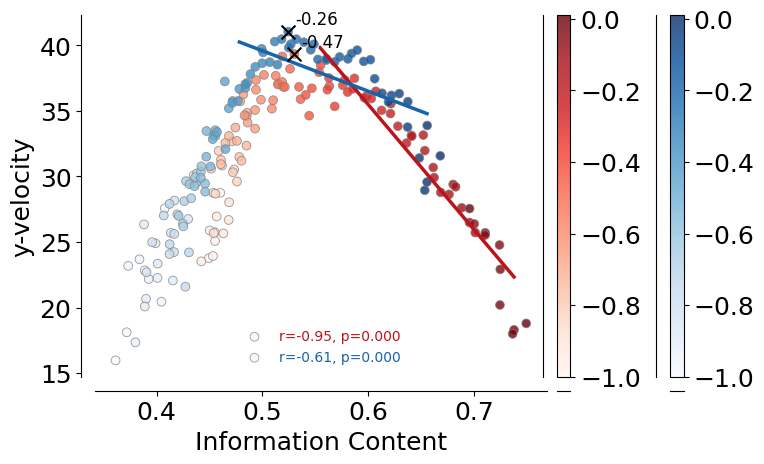

In [60]:
# Correlation between velocity and info gain (binned means)
vel_binned = binned_by_metric["velocity_y"]
info_binned = binned_by_metric["info_gain"]
corr_df = vel_binned.merge(
    info_binned,
    on=["aperture", "t_bin"],
    suffixes=("_vel", "_info"),
)

corr_window = (-0.4, 0.0)

fig, ax = plt.subplots(1, 1, figsize=(8, 5))
divider = make_axes_locatable(ax)
apertures_sorted = sorted(corr_df.aperture.unique())[:2]

cmap_by_ap = {
    apertures_sorted[0]: "Reds",
    apertures_sorted[1]: "Blues",
}

for i, ap in enumerate(apertures_sorted):
    # Full data for the scatter plot
    ap_df = corr_df[corr_df.aperture == ap].dropna(subset=["mean_info", "mean_vel"])
    if ap_df.empty:
        continue
    
    # Find the row with the maximum velocity for this aperture
    max_row = ap_df.loc[ap_df["mean_vel"].idxmax()]
    max_x = max_row["mean_info"]
    max_y = max_row["mean_vel"]
    max_time = max_row["t_bin"]
    
    ax.scatter(max_x, max_y, marker='x', s=100, color='black', 
                zorder=10)
    ax.annotate(
        f"{max_time:.2f}", 
        xy=(max_x, max_y), 
        xytext=(5, 5), 
        textcoords='offset points',
        fontsize=12,
    )

    # Subset data for Pearson Correlation and Regression
    mask = (ap_df.t_bin >= corr_window[0]) & (ap_df.t_bin <= corr_window[1])
    #mask = (ap_df.t_bin >= max_time) & (ap_df.t_bin <= 0)
    stat_df = ap_df[mask]
    
    if not stat_df.empty:
        r_coeff, p_val = pearsonr(stat_df["mean_info"], stat_df["mean_vel"])
        label_str = f"r={r_coeff:.2f}, p={p_val:.3f}"
        
        # Plot regression line for the given window
        slope, intercept = np.polyfit(stat_df["mean_info"], stat_df["mean_vel"], 1)
        x_range = np.linspace(stat_df["mean_info"].min(), stat_df["mean_info"].max(), 10)
        ax.plot(x_range, slope * x_range + intercept, 
                color=plt.get_cmap(cmap_by_ap[ap])(0.8), linewidth=2.5, zorder=5)

    # Plot ALL scatter points
    sc = ax.scatter(
        ap_df["mean_info"],
        ap_df["mean_vel"],
        c=ap_df["t_bin"],
        cmap=cmap_by_ap[ap],
        s=40,
        edgecolors="grey",
        linewidths=0.6,
        label=label_str,
        alpha=0.8
    )

    # Handle Colorbars
    cax = divider.append_axes("right", size="3%", pad=0.1 + (i * 0.9))
    cbar = fig.colorbar(sc, cax=cax, shrink=True)

ax.set_xlabel("Information Content")
ax.set_ylabel("y-velocity")
leg = ax.legend(frameon=False)

for i, text in enumerate(leg.get_texts()):
    ap_key = apertures_sorted[i]
    text.set_color(plt.get_cmap(cmap_by_ap[ap_key])(0.8))

sns.despine(offset=10)
plt.tight_layout(pad=2.0)

plt.savefig(save_fig_path + "figure4_info_velocity_correlation_y.svg", transparent=True)

### Information contained at decision point per condition

In [61]:
interpolated_df = interpolated_df.sort_values(by=["mouse_name", "dataset"])
#interpolated_df["session_idx"] = interpolated_df.groupby(["mouse_name").cumcount() + 1

session_map = interpolated_df.groupby(["mouse_name", "dataset"]).ngroup()
interpolated_df["session_idx"] = interpolated_df.groupby("mouse_name")["dataset"].transform(lambda x: x.map({val: i+1 for i, val in enumerate(x.unique())}))

In [62]:
decision_points["trial_length"] = decision_points["trial_length"].astype(float)

In [63]:
# for each trial, get the initial position
initial_positions = interpolated_df.groupby(
    ["mouse_name", "dataset", "aperture", "trial"], as_index=False
).first()[["mouse_name", "dataset", "aperture", "trial", "x", "y"]]

# Get info at initial position
initial_positions["info_gain"] = initial_positions.apply(
    lambda row: get_info_at_position(
        info_matrices[0] if row.aperture == 4.3 else info_matrices[1],
        (row.x, row.y),
    ),
    axis=1,
)

In [64]:
# Decision point information available
info_at_decision_per_session = decision_points.groupby(["mouse_name", "dataset", "aperture"], as_index=False).mean(numeric_only=True)
info_at_decision_per_session = info_at_decision_per_session.rename(columns={None: "info_gain"})
info_at_decision_per_session["count"] = info_at_decision_per_session["info_gain"]
info_at_decision_per_session.aperture = info_at_decision_per_session.aperture.astype(float).round(2).astype(str)
info_at_decision_per_session = pd.DataFrame(info_at_decision_per_session.reset_index())

# Initial position information available
initial_positions = initial_positions.groupby(["mouse_name", "dataset", "aperture"], as_index=False)["info_gain"].mean()
initial_positions["count"] = initial_positions["info_gain"]
initial_positions.aperture = initial_positions.aperture.astype(float).round(2).astype(str)
initial_positions = pd.DataFrame(initial_positions.reset_index())

In [65]:
# Merge the two dataframes on the common keys
information_difference = pd.merge(
    info_at_decision_per_session[["mouse_name", "dataset", "aperture", "info_gain"]],
    initial_positions[["mouse_name", "dataset", "aperture", "info_gain"]],
    on=["mouse_name", "dataset", "aperture"],
    suffixes=("_decision", "_initial")
)

# Calculate the delta
information_difference["info_gain"] = (
    information_difference["info_gain_decision"] - information_difference["info_gain_initial"]
)
information_difference["count"] = information_difference["info_gain"]
information_difference = information_difference.drop(columns=["info_gain_decision", "info_gain_initial"])

Information at Initiation
15.0-5.0: TtestResult(statistic=1.401258101672069, pvalue=0.23375269845093768, df=4)
Information at Decision
15.0-5.0: TtestResult(statistic=-28.042286221922637, pvalue=9.621098757635296e-06, df=4)
Information Difference
15.0-5.0: TtestResult(statistic=-25.994143530930927, pvalue=1.301296897353795e-05, df=4)


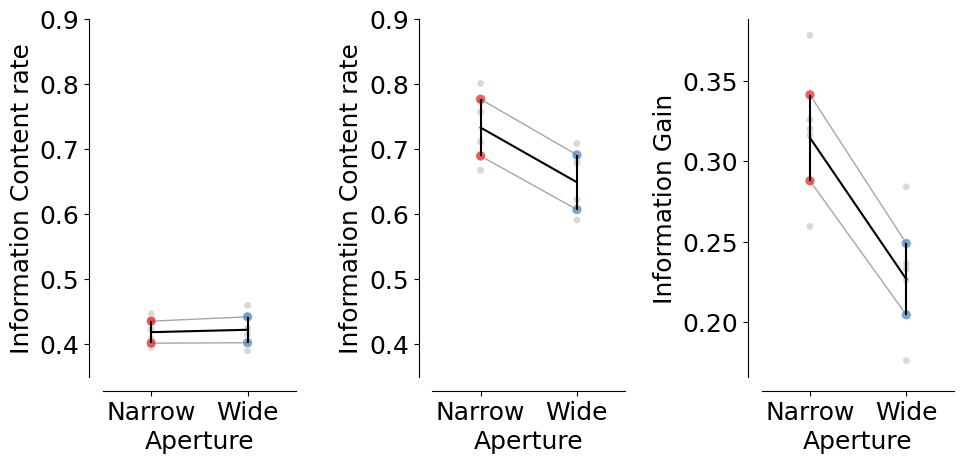

In [68]:
fig, ax = plt.subplots(1, 3, figsize=(10, 5))

plotting._plot_bar_counts(
    counts=initial_positions.sort_values("aperture", ascending=False),
    label_x="aperture",
    alpha=0.3,
    ax=ax[0],
    per_mouse=True,
    cmap=plotting.colors_aperture[0:2],
)
ax[0].invert_xaxis()
ax[0].set_ylabel("Information Content rate")
ax[0].set_xlim(-0.5, 1.5)
ax[0].set_xticks([0, 1], ["Narrow", "Wide"])
ax[0].set_xlabel("Aperture")
ax[0].legend([], [], frameon=False)
sns.despine(offset=10, ax=ax[0])

plotting._plot_bar_counts(
    counts=info_at_decision_per_session,
    label_x="aperture",
    alpha=0.3,
    ax=ax[1],
    per_mouse=True,
    cmap=plotting.colors_aperture[0:2],
)
ax[1].invert_xaxis()
ax[1].set_ylabel("Information Content rate")
ax[1].set_xlim(-0.5, 1.5)
ax[1].set_xticks([0, 1], ["Narrow", "Wide"])
ax[1].set_xlabel("Aperture")
ax[1].legend([], [], frameon=False)
sns.despine(offset=10, ax=ax[1])

plotting._plot_bar_counts(
    counts=information_difference.sort_values("aperture", ascending=False),
    label_x="aperture",
    alpha=0.3,
    ax=ax[2],
    per_mouse=True,
    cmap=plotting.colors_aperture[0:2],
)
ax[2].invert_xaxis()
ax[2].set_ylabel("Information Gain")
ax[2].set_xlim(-0.5, 1.5)
ax[2].set_xticks([0, 1], ["Narrow", "Wide"])
ax[2].set_xlabel("Aperture")
ax[2].legend([], [], frameon=False)
sns.despine(offset=10, ax=ax[2])

ax[0].set_ylim(0.35, 0.9)
ax[1].set_ylim(0.35, 0.9)

plt.tight_layout(pad=2)
plt.savefig(
    save_fig_path + "figure4_information_quantification.svg",
    transparent=True,
)

for info, label in zip([initial_positions, info_at_decision_per_session, information_difference],
                       ["Information at Initiation", "Information at Decision", "Information Difference"]):
    print(label)
    for i in info.aperture.unique():
        for j in info.aperture.unique():
            if i < j:
                stat = stats.ttest_rel(
                    info[info["aperture"] == i]["count"],
                    info[info["aperture"] == j]["count"],
                )
                print(f"{i}-{j}: {stat}")

In [67]:
# Get mean + sem for all 
for info, label in zip([initial_positions, info_at_decision_per_session, information_difference],
                       ["Information at Initiation", "Information at Decision", "Information Difference"]):
    print(label)
    # round to 2 decimals
    print(info.groupby("aperture")["count"].mean().round(3))
    print(info.groupby("aperture")["count"].sem().round(3))

Information at Initiation
aperture
15.0    0.426
5.0     0.422
Name: count, dtype: float64
aperture
15.0    0.012
5.0     0.009
Name: count, dtype: float64
Information at Decision
aperture
15.0    0.658
5.0     0.742
Name: count, dtype: float64
aperture
15.0    0.022
5.0     0.024
Name: count, dtype: float64
Information Difference
aperture
15.0    0.231
5.0     0.320
Name: count, dtype: float64
aperture
15.0    0.017
5.0     0.019
Name: count, dtype: float64


### Distance to screen of the decision points per condition

In [69]:
decision_points["y"] = decision_points["y"].astype(float)
decision_points["distance_to_screen"] = np.abs(decision_points["y"] - 27)

mean: 8.095787113992266 +/- 1.2616203480326145
15.0-5.0: TtestResult(statistic=30.988118553820982, pvalue=6.46191603431424e-06, df=4)
 mean difference:  -4.586262448251453
mean: 12.68204956224372 +/- 1.4000632289534323


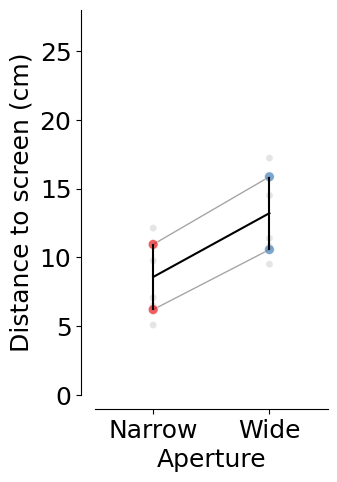

In [70]:
fig, ax = plt.subplots(1, 1, figsize=(3, 5))

counts, stats_mean = plotting.pairplot_average_decision_point(
    decision_points,
    label_parameter="distance_to_screen",
    ax=ax,
    cmap=plotting.colors_aperture,
    per_mouse=True,
)
ax.set_xlim(-0.5, 1.5)
ax.set_ylim(0, 28)
ax.set_xlabel("Aperture")
ax.set_xticks([0, 1], ["Narrow", "Wide"])
ax.set_ylabel("Distance to screen (cm)")
sns.despine(offset=10)
plt.legend([], [], frameon=False)

plt.savefig(
    save_fig_path + "figure4_decision_points_distance.svg",
    transparent=True,
)

In [71]:
decision_points["lab_id"] = 0
for dataset_name in sessions_list:
    # Fetch lab_id for each dataset
    decision_points.loc[decision_points.dataset==dataset_name, "lab_id"] = ((vr4mice.Collab() & f'dataset = "{dataset_name}"') * vr4mice.Labs()).fetch("lab")[0]

/tmp/ipykernel_77212/1189363056.py:4: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  decision_points.loc[decision_points.dataset==dataset_name, "lab_id"] = ((vr4mice.Collab() & f'dataset = "{dataset_name}"') * vr4mice.Labs()).fetch("lab")[0]
/tmp/ipykernel_77212/1189363056.py:4: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  decision_points.loc[decision_points.dataset==dataset_name, "lab_id"] = ((vr4mice.Collab() & f'dataset = "{dataset_name}"') * vr4mice.Labs()).fetch("lab")[0]
/tmp/ipykernel_77212/1189363056.py:4: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  decision_points.loc[decision_points.dataset==dataset_name, "lab_id"] = ((vr4mice.Collab() & f'dataset = "{dataset_name}"') * vr4mice.Labs()).fetch("lab")[0]
/tmp/ipykernel_77212/1189363056.py:4: Deprecat

mean: 18.904212886007734 +/- 1.2616203480326147
15.0-5.0: TtestResult(statistic=-30.98811855382086, pvalue=6.4619160343143325e-06, df=4)
 mean difference:  4.586262448251453
mean: 14.31795043775628 +/- 1.4000632289534327


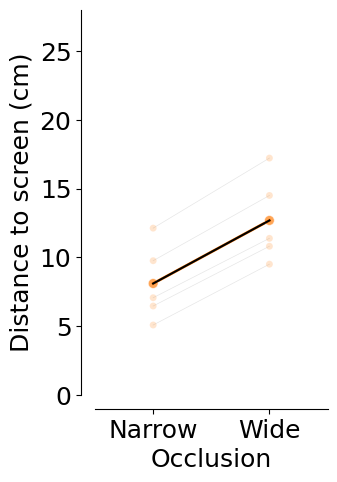

In [72]:
fig, ax = plt.subplots(1, 1, figsize=(3, 5))
stats_mean = plotting.pairplot_average_decision_point(
    decision_points,
    label_parameter="y",
    ax=ax,
    cmap=plotting.colors_aperture,
    per_lab=True,
)
ax.set_xlim(-0.5, 1.5)
ax.set_ylim(0, 28)
ax.set_xlabel("Occlusion")
ax.set_xticks([0, 1], ["Narrow", "Wide"])
ax.set_ylabel("Distance to screen (cm)")
sns.despine(offset=10)
plt.legend([], [], frameon=False)

plt.savefig(
    save_fig_path + "figure4_decision_points_distance_per_lab.svg",
    transparent=True,
)

In [73]:
decision_points_stats = decision_points.groupby(["dataset", "aperture"], as_index=False)[
    "y"
].mean()
anova_rm = AnovaRM(decision_points_stats, depvar="y", subject="dataset", within=["aperture"])

anova_results = anova_rm.fit()
anova_table = anova_results.summary()
print(anova_table)

                Anova
         F Value  Num DF Den DF Pr > F
--------------------------------------
aperture 960.2635 1.0000 4.0000 0.0000



In [74]:
decision_points.groupby("aperture").y.mean(), decision_points.groupby("aperture").y.sem()

(aperture
 5.0     19.146965
 15.0    14.557902
 Name: y, dtype: float64,
 aperture
 5.0     0.239230
 15.0    0.303091
 Name: y, dtype: float64)

## Investigating first test session

In [83]:
interpolated_df["date"] = pd.to_datetime(interpolated_df["dataset"].str.split("_").str[1])
interpolated_df.sort_values(by=["mouse_name", "date"], inplace=True)

In [84]:
import copy
temp_interpolated_df = copy.deepcopy(interpolated_df)

temp_interpolated_df = temp_interpolated_df[temp_interpolated_df.mouse_name != "J731"]
temp_interpolated_df["y"] = temp_interpolated_df["y"]
first_datasets = temp_interpolated_df[(temp_interpolated_df.trial == 20) & (temp_interpolated_df.trial_length == 0.0)].groupby('mouse_name').first()["dataset"]
second_datasets = temp_interpolated_df[(temp_interpolated_df.trial == 20) & (temp_interpolated_df.trial_length == 0.0)].groupby('mouse_name').apply(lambda x: x.iloc[1])["dataset"]

/tmp/ipykernel_77212/1257764120.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  second_datasets = temp_interpolated_df[(temp_interpolated_df.trial == 20) & (temp_interpolated_df.trial_length == 0.0)].groupby('mouse_name').apply(lambda x: x.iloc[1])["dataset"]


In [85]:
# and for decision points
first_decision_points = decision_points[decision_points.dataset.isin(first_datasets)]
#first_decision_points = first_decision_points[~first_decision_points.mouse_name.isin(["J731"])]

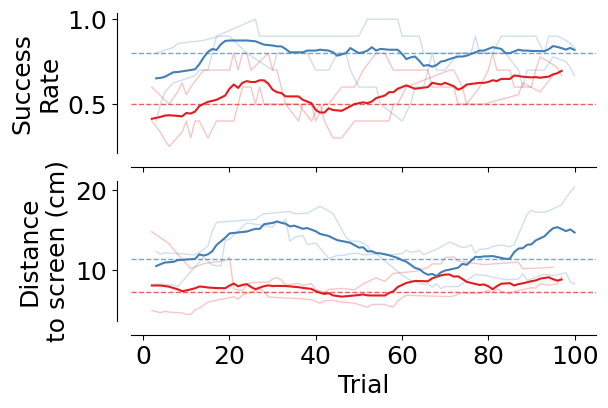

In [89]:
fig, ax = plt.subplots(2, 1, figsize=(6, 4), sharex=True)

window_size = 10
n_trials = 100

for aperture, color in zip([5, 15], plotting.colors_aperture):
    plotting.plot_mouse_trial_lineplot(first_decision_points[(first_decision_points.aperture==aperture) & (first_decision_points.trial <= n_trials)], 
                                       "trial_rewarded", 
                                        ax=ax[0],
                                        rolling_window=window_size,
                                        color=color,
                                        normalize=False)
    
    plotting.plot_mouse_trial_lineplot(first_decision_points[(first_decision_points.aperture==aperture) & (first_decision_points.trial <= n_trials)], 
                                       "distance_to_screen",
                                        ax=ax[1],
                                        rolling_window=window_size,
                                        color=color,
                                        normalize=False)

ax[0].set_title("")
ax[1].set_title("")
ax[0].set_xlabel("")

ax[0].set_ylabel("Success\nRate")
ax[1].set_ylabel("Distance\nto screen (cm)")

for ax in ax.flatten():
    sns.despine(offset=10, ax=ax)
    
plt.savefig(save_fig_path + "figure4_first_session.svg", transparent=True, bbox_inches="tight")

## Decision point distance to screen vs. reward rate across successful and less successful sessions [wide occlusion]
Including sessions with the narrow-wide difference in reward rate > 0.25

In [90]:
trial_df_all_wide = (TrialMetrics() * (vr4mice.Dataset() & 'session_label = "ar_shape_discrim_occluders"') * (vr4mice.DatasetBatch() & {"batch_name": BATCH_NAME}) & vr4mice.ExcludedDataset.exclusion_filter()).fetch(as_dict=True)
trial_df_all_wide =  pd.concat([pd.DataFrame(x) for x in trial_df_all_wide])

# Exclude sessions that were not in the list
trial_df_all_wide, reward_table = utils.apply_inclusion_criteria(trial_df_all_wide,
                                                        return_excluded=False,
                                                        consider_reward_drop=False)


trial_df_all_wide["mouse_name"] = trial_df_all_wide.dataset.str.split("_").str[0]

/tmp/ipykernel_77212/2642158063.py:1: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  trial_df_all_wide = (TrialMetrics() * (vr4mice.Dataset() & 'session_label = "ar_shape_discrim_occluders"') * (vr4mice.DatasetBatch() & {"batch_name": BATCH_NAME}) & vr4mice.ExcludedDataset.exclusion_filter()).fetch(as_dict=True)


In [91]:
trial_df_all_wide = trial_df_all_wide[trial_df_all_wide.aperture.isin([8, 15])]

# Create list of included datasets
sessions_list_all_wide = trial_df_all_wide.dataset.unique()

In [92]:
dataset_list_all_wide = []
for d in sessions_list_all_wide:
    print(d)
    try:
        if len(InterpolatedTrials() & f'dataset = "{d}"') > 0:
            dataset_list_all_wide.append(pd.DataFrame((InterpolatedTrials() & f'dataset = "{d}"').fetch(as_dict=True)[0]))
        else:
            print("dataset missing")
    except Exception as err:
        print(err, " dataset missing")
interpolated_df_all_wide = pd.concat(dataset_list_all_wide)
interpolated_df_all_wide["mouse_name"] = interpolated_df_all_wide.dataset.str.split("_").str [0]

Uguisu_2024-09-17_1


/tmp/ipykernel_77212/2276084277.py:6: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  dataset_list_all_wide.append(pd.DataFrame((InterpolatedTrials() & f'dataset = "{d}"').fetch(as_dict=True)[0]))


Uguisu_2024-09-18_1


/tmp/ipykernel_77212/2276084277.py:6: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  dataset_list_all_wide.append(pd.DataFrame((InterpolatedTrials() & f'dataset = "{d}"').fetch(as_dict=True)[0]))


Uguisu_2024-09-19_1


...

/tmp/ipykernel_77212/2276084277.py:6: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  dataset_list_all_wide.append(pd.DataFrame((InterpolatedTrials() & f'dataset = "{d}"').fetch(as_dict=True)[0]))


Wiwaxia_2024-09-24_1


/tmp/ipykernel_77212/2276084277.py:6: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  dataset_list_all_wide.append(pd.DataFrame((InterpolatedTrials() & f'dataset = "{d}"').fetch(as_dict=True)[0]))


Wiwaxia_2024-09-25_1


/tmp/ipykernel_77212/2276084277.py:6: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  dataset_list_all_wide.append(pd.DataFrame((InterpolatedTrials() & f'dataset = "{d}"').fetch(as_dict=True)[0]))


In [93]:
interpolated_df_all_wide.dataset.nunique(), interpolated_df_all_wide.mouse_name.nunique()

(9, 3)

In [94]:
model_labels, clean_labels, label_set_name = (
        LabelSet.Member * Label * LabelSet & f"label_set_id='8'").fetch(
            "label_key", "clean_name", "label_set_name")

/tmp/ipykernel_77212/2714987085.py:2: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  LabelSet.Member * Label * LabelSet & f"label_set_id='8'").fetch(


In [95]:
WINDOW_COUNT = 10

# Build trial-progress windows like PredictionModel10Windows
df_multi = interpolated_df_all_wide.copy()
df_multi["aperture"] = df_multi["aperture"].astype(float)
df_multi = df_multi.sort_values(["dataset", "trial", "trial_length"]).reset_index(drop=True)

trial_index = df_multi.groupby(["dataset", "trial"]).cumcount()
trial_size = df_multi.groupby(["dataset", "trial"])["trial"].transform("size")
df_multi["trial_window"] = np.clip(
    (trial_index * WINDOW_COUNT / trial_size).astype(int),
    0,
    WINDOW_COUNT - 1,
)

# Train one model per window (LOGO across datasets)
df_model_parts = []
coef = {}
scalers_by_window = {}

for window_id in range(WINDOW_COUNT):
    window_df = df_multi[df_multi["trial_window"] == window_id].copy()
    if window_df.empty:
        coef[window_id] = np.array([[np.nan]])
        scalers_by_window[window_id] = []
        continue

    window_pred, window_coef, window_scalers = regression.predict_decision(
        df=window_df,
        label=model_labels,
        per_session=True,
    )

    window_pred["model_idx"] = window_id
    df_model_parts.append(window_pred)

    coef[window_id] = window_coef
    scalers_by_window[window_id] = window_scalers

df_model_all_wide = pd.concat(df_model_parts, ignore_index=True)
df_model_all_wide = df_model_all_wide.sort_values(
    ["dataset", "trial", "trial_length", "model_idx"]
).reset_index(drop=True)

# Optional sanity check: every sample assigned to exactly one window model
assert len(df_model_all_wide) == len(df_multi), "Row mismatch after windowed prediction"

In [96]:
decision_points_all_wide = regression.find_decision_point(df_model_all_wide, 
                                                 threshold_uncertainty=0.1)

In [97]:
decision_points_all_wide["distance_to_screen"] = np.abs(decision_points_all_wide["y"] - 27)

In [98]:
for aperture, color, ypos in zip(decision_points_all_wide.sort_values("aperture").aperture.unique(), 
                                     plotting.colors_aperture,
                                     [0.10, 0.05]):
    x = abs(decision_points_all_wide[decision_points_all_wide.aperture==aperture].groupby(
        "mouse_name")["y"].mean().values - 27)

Aperture 8.0: r=0.5282986647075681, p=0.6456602847738871
Aperture 15.0: r=-0.011250156506349716, p=0.9928377768380614


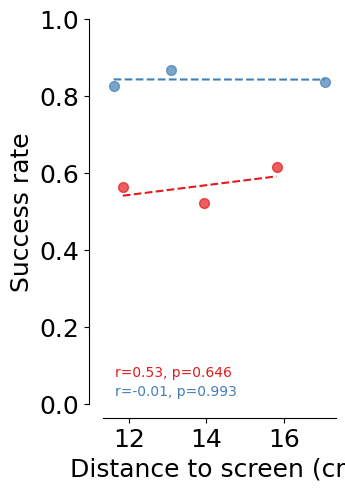

In [99]:
fig, ax = plt.subplots(1, 1, figsize=(3, 5))

for aperture, color, ypos in zip(decision_points_all_wide.sort_values("aperture").aperture.unique(), 
                                     plotting.colors_aperture,
                                     [0.10, 0.05]):
    x = abs(decision_points_all_wide[decision_points_all_wide.aperture==aperture].groupby(
        "mouse_name")["y"].mean().values - 27)
    y = trial_df_all_wide[(trial_df_all_wide.aperture==aperture)].groupby(
        "mouse_name")["trial_rewarded"].mean().values


    # scatter
    ax.scatter(
        x, y,
        color=color,
        alpha=0.7,
        s=50
    )

    # regression line
    slope, intercept, r_value, p_value, std_err = stats.linregress(x, y)
    x_fit = np.linspace(x.min(), x.max(), 100)
    y_fit = slope * x_fit + intercept
    ax.plot(x_fit, y_fit, color=color, linestyle="--")
    
    print(f"Aperture {aperture}: r={r_value}, p={p_value}")

    # annotate correlation
    ax.text(
        0.05, ypos,
        f"r={r_value:.2f}, p={p_value:.3g}",
        transform=ax.transAxes,
        va="top", ha="left",
        color=color
    )

    ax.set_xlabel("Distance to screen (cm)")
    ax.set_ylabel("Success rate")
    ax.set_ylim(0, 1.0)
    sns.despine(offset=10, ax=ax)

plt.savefig(save_fig_path + "figure4_decision_point_vs_performance.svg", transparent=True)

## [WIDE] Investigating first test session with the ones dropped

In [100]:
interpolated_df_all_wide["date"] = pd.to_datetime(interpolated_df_all_wide["dataset"].str.split("_").str[1])
interpolated_df_all_wide.sort_values(by=["mouse_name", "date"], inplace=True)

In [121]:
import copy
temp_interpolated_df = copy.deepcopy(interpolated_df_all_wide)

# Drop Wiwaxia as she is excluded from the analyses above already
temp_interpolated_df = temp_interpolated_df[temp_interpolated_df.mouse_name != "Wiwaxia"]

temp_interpolated_df["y"] = temp_interpolated_df["y"]
first_datasets = temp_interpolated_df[(temp_interpolated_df.trial == 20) & (temp_interpolated_df.trial_length == 0.0)].groupby('mouse_name').first()["dataset"]
#second_datasets = temp_interpolated_df[(temp_interpolated_df.trial == 20) & (temp_interpolated_df.trial_length == 0.0)].groupby('mouse_name').apply(lambda x: x.iloc[1])["dataset"]

In [122]:
# and for decision points
first_decision_points = decision_points_all_wide[decision_points_all_wide.dataset.isin(first_datasets)]

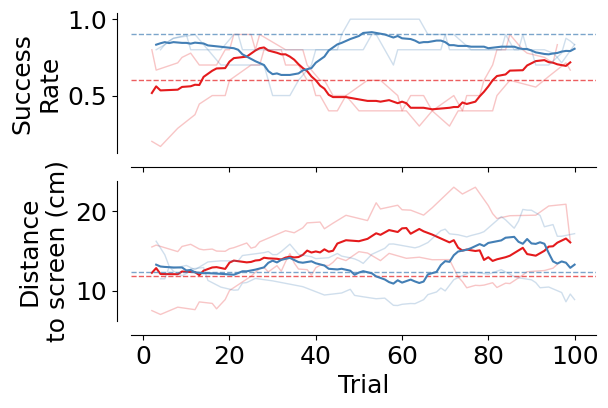

In [124]:
fig, ax = plt.subplots(2, 1, figsize=(6, 4), sharex=True)

window_size = 10
n_trials = 100

for aperture, color in zip([8, 15], plotting.colors_aperture):
    plotting.plot_mouse_trial_lineplot(first_decision_points[(first_decision_points.aperture==aperture) & (first_decision_points.trial <= n_trials)], 
                                       "trial_rewarded", 
                                        ax=ax[0],
                                        rolling_window=window_size,
                                        color=color,
                                        normalize=False)
    
    plotting.plot_mouse_trial_lineplot(first_decision_points[(first_decision_points.aperture==aperture) & (first_decision_points.trial <= n_trials)], 
                                       "distance_to_screen",
                                        ax=ax[1],
                                        rolling_window=window_size,
                                        color=color,
                                        normalize=False)

ax[0].set_title("")
ax[1].set_title("")
ax[0].set_xlabel("")

ax[0].set_ylabel("Success\nRate")
ax[1].set_ylabel("Distance\nto screen (cm)")

for ax in ax.flatten():
    sns.despine(offset=10, ax=ax)
    
plt.savefig(save_fig_path + "figure4_first_session.svg", transparent=True, bbox_inches="tight")

## Decision point distance to screen vs. reward rate across successful and less successful sessions
Including sessions with the narrow-wide difference in reward rate > 0.25

In [125]:
trial_df_all = (TrialMetrics() * (vr4mice.Dataset() & 'session_label = "ar_shape_discrim_narrow_occluders"') * (vr4mice.DatasetBatch() & {"batch_name": BATCH_NAME}) & vr4mice.ExcludedDataset.exclusion_filter()).fetch(as_dict=True)
trial_df_all =  pd.concat([pd.DataFrame(x) for x in trial_df_all])

# Exclude sessions that were not in the list
trial_df_all, reward_table = utils.apply_inclusion_criteria(trial_df_all,
                                                        return_excluded=False,
                                                        consider_reward_drop=False)


trial_df_all["mouse_name"] = trial_df_all.dataset.str.split("_").str[0]

/tmp/ipykernel_77212/3365801176.py:1: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  trial_df_all = (TrialMetrics() * (vr4mice.Dataset() & 'session_label = "ar_shape_discrim_narrow_occluders"') * (vr4mice.DatasetBatch() & {"batch_name": BATCH_NAME}) & vr4mice.ExcludedDataset.exclusion_filter()).fetch(as_dict=True)


In [105]:
trial_df_all = trial_df_all[trial_df_all.aperture.isin([5, 15])]

# Create list of included datasets
sessions_list_all = trial_df_all.dataset.unique()

In [106]:
dataset_list_all = []
for d in sessions_list_all:
    print(d)
    try:
        if len(InterpolatedTrials() & f'dataset = "{d}"') > 0:
            dataset_list_all.append(pd.DataFrame((InterpolatedTrials() & f'dataset = "{d}"').fetch(as_dict=True)[0]))
        else:
            print("dataset missing")
    except Exception as err:
        print(err, " dataset missing")
interpolated_df_all = pd.concat(dataset_list_all)
interpolated_df_all["mouse_name"] = interpolated_df_all.dataset.str.split("_").str [0]

/tmp/ipykernel_77212/1643370164.py:6: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  dataset_list_all.append(pd.DataFrame((InterpolatedTrials() & f'dataset = "{d}"').fetch(as_dict=True)[0]))


Uguisu_2024-09-23_1
Uguisu_2024-09-24_1


/tmp/ipykernel_77212/1643370164.py:6: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  dataset_list_all.append(pd.DataFrame((InterpolatedTrials() & f'dataset = "{d}"').fetch(as_dict=True)[0]))


Uguisu_2024-09-25_1
dataset missing
Uguisu_2024-09-25_2


/tmp/ipykernel_77212/1643370164.py:6: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  dataset_list_all.append(pd.DataFrame((InterpolatedTrials() & f'dataset = "{d}"').fetch(as_dict=True)[0]))


...

/tmp/ipykernel_77212/1643370164.py:6: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  dataset_list_all.append(pd.DataFrame((InterpolatedTrials() & f'dataset = "{d}"').fetch(as_dict=True)[0]))


Vegavis_2024-09-25_1


/tmp/ipykernel_77212/1643370164.py:6: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  dataset_list_all.append(pd.DataFrame((InterpolatedTrials() & f'dataset = "{d}"').fetch(as_dict=True)[0]))


Vegavis_2024-09-26_1


/tmp/ipykernel_77212/1643370164.py:6: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  dataset_list_all.append(pd.DataFrame((InterpolatedTrials() & f'dataset = "{d}"').fetch(as_dict=True)[0]))


In [107]:
interpolated_df_all.dataset.nunique(), interpolated_df_all.mouse_name.nunique()

(7, 2)

In [108]:
model_labels, clean_labels, label_set_name = (
        LabelSet.Member * Label * LabelSet & f"label_set_id='8'").fetch(
            "label_key", "clean_name", "label_set_name")

/tmp/ipykernel_77212/2714987085.py:2: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  LabelSet.Member * Label * LabelSet & f"label_set_id='8'").fetch(


In [109]:
WINDOW_COUNT = 10

# Build trial-progress windows like PredictionModel10Windows
df_multi = interpolated_df_all.copy()
df_multi["aperture"] = df_multi["aperture"].astype(float)
df_multi = df_multi.sort_values(["dataset", "trial", "trial_length"]).reset_index(drop=True)

trial_index = df_multi.groupby(["dataset", "trial"]).cumcount()
trial_size = df_multi.groupby(["dataset", "trial"])["trial"].transform("size")
df_multi["trial_window"] = np.clip(
    (trial_index * WINDOW_COUNT / trial_size).astype(int),
    0,
    WINDOW_COUNT - 1,
)

# Train one model per window (LOGO across datasets)
df_model_parts = []
coef = {}
scalers_by_window = {}

for window_id in range(WINDOW_COUNT):
    window_df = df_multi[df_multi["trial_window"] == window_id].copy()
    if window_df.empty:
        coef[window_id] = np.array([[np.nan]])
        scalers_by_window[window_id] = []
        continue

    window_pred, window_coef, window_scalers = regression.predict_decision(
        df=window_df,
        label=model_labels,
        per_session=True,
    )

    window_pred["model_idx"] = window_id
    df_model_parts.append(window_pred)

    coef[window_id] = window_coef
    scalers_by_window[window_id] = window_scalers

df_model_all = pd.concat(df_model_parts, ignore_index=True)
df_model_all = df_model_all.sort_values(
    ["dataset", "trial", "trial_length", "model_idx"]
).reset_index(drop=True)

# Optional sanity check: every sample assigned to exactly one window model
assert len(df_model_all) == len(df_multi), "Row mismatch after windowed prediction"

In [110]:
decision_points_all = regression.find_decision_point(df_model_all, 
                                                 threshold_uncertainty=0.1)

In [111]:
decision_points_all["distance_to_screen"] = np.abs(decision_points_all["y"] - 27)

In [112]:
for aperture, color, ypos in zip(decision_points_all.sort_values("aperture").aperture.unique(), 
                                     plotting.colors_aperture,
                                     [0.10, 0.05]):
    x = abs(decision_points_all[decision_points_all.aperture==aperture].groupby(
        "mouse_name")["y"].mean().values - 27)

Aperture 5.0: r=1.0, p=0.0
Aperture 15.0: r=1.0, p=0.0


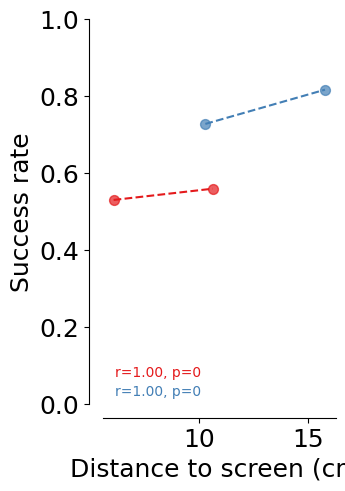

In [113]:
fig, ax = plt.subplots(1, 1, figsize=(3, 5))

for aperture, color, ypos in zip(decision_points_all.sort_values("aperture").aperture.unique(), 
                                     plotting.colors_aperture,
                                     [0.10, 0.05]):
    x = abs(decision_points_all[decision_points_all.aperture==aperture].groupby(
        "mouse_name")["y"].mean().values - 27)
    y = trial_df_all[(trial_df_all.aperture==aperture)].groupby(
        "mouse_name")["trial_rewarded"].mean().values


    # scatter
    ax.scatter(
        x, y,
        color=color,
        alpha=0.7,
        s=50
    )

    # regression line
    slope, intercept, r_value, p_value, std_err = stats.linregress(x, y)
    x_fit = np.linspace(x.min(), x.max(), 100)
    y_fit = slope * x_fit + intercept
    ax.plot(x_fit, y_fit, color=color, linestyle="--")
    
    print(f"Aperture {aperture}: r={r_value}, p={p_value}")

    # annotate correlation
    ax.text(
        0.05, ypos,
        f"r={r_value:.2f}, p={p_value:.3g}",
        transform=ax.transAxes,
        va="top", ha="left",
        color=color
    )

    ax.set_xlabel("Distance to screen (cm)")
    ax.set_ylabel("Success rate")
    ax.set_ylim(0, 1.0)
    sns.despine(offset=10, ax=ax)

plt.savefig(save_fig_path + "figure4_decision_point_vs_performance.svg", transparent=True)

## Investigating first test session with the ones dropped

In [114]:
interpolated_df_all["date"] = pd.to_datetime(interpolated_df_all["dataset"].str.split("_").str[1])
interpolated_df_all.sort_values(by=["mouse_name", "date"], inplace=True)

In [126]:
import copy
temp_interpolated_df = copy.deepcopy(interpolated_df_all)

temp_interpolated_df["y"] = temp_interpolated_df["y"]
first_datasets = temp_interpolated_df[(temp_interpolated_df.trial == 20) & (temp_interpolated_df.trial_length == 0.0)].groupby('mouse_name').first()["dataset"]
#second_datasets = temp_interpolated_df[(temp_interpolated_df.trial == 20) & (temp_interpolated_df.trial_length == 0.0)].groupby('mouse_name').apply(lambda x: x.iloc[1])["dataset"]

In [127]:
# and for decision points
first_decision_points = decision_points_all[decision_points_all.dataset.isin(first_datasets)]
#first_decision_points = first_decision_points[~first_decision_points.mouse_name.isin(["J731"])]

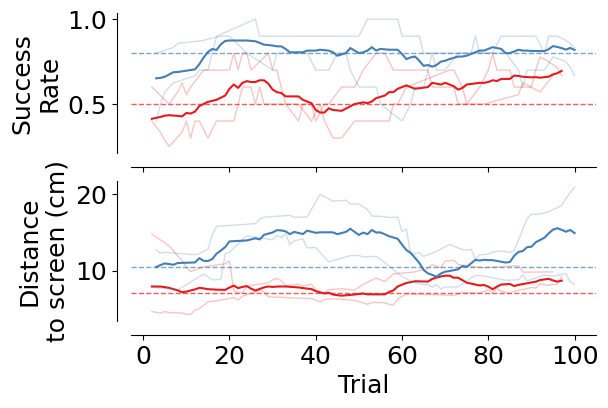

In [128]:
fig, ax = plt.subplots(2, 1, figsize=(6, 4), sharex=True)

window_size = 10
n_trials = 100

for aperture, color in zip([5, 15], plotting.colors_aperture):
    plotting.plot_mouse_trial_lineplot(first_decision_points[(first_decision_points.aperture==aperture) & (first_decision_points.trial <= n_trials)], 
                                       "trial_rewarded", 
                                        ax=ax[0],
                                        rolling_window=window_size,
                                        color=color,
                                        normalize=False)
    
    plotting.plot_mouse_trial_lineplot(first_decision_points[(first_decision_points.aperture==aperture) & (first_decision_points.trial <= n_trials)], 
                                       "distance_to_screen",
                                        ax=ax[1],
                                        rolling_window=window_size,
                                        color=color,
                                        normalize=False)

ax[0].set_title("")
ax[1].set_title("")
ax[0].set_xlabel("")

ax[0].set_ylabel("Success\nRate")
ax[1].set_ylabel("Distance\nto screen (cm)")

for ax in ax.flatten():
    sns.despine(offset=10, ax=ax)
    
plt.savefig(save_fig_path + "figure4_first_session.svg", transparent=True, bbox_inches="tight")